# Calculating fundamental Curvatures for the 3D metric

In [2]:
import sympy as sp
from IPython.display import display, Math
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
# 1. Coordinates
# ======================================================
x, y, z = sp.symbols('x y z', real=True)  # Specify the coordinate system here
coords = [x, y, z]  # This collectes the coordinates so that we can differentiate using coords[i]

n = len(coords) # Dimension of the manifold

# ======================================================
# 2. Metric Tensor (EDIT THIS)
# ======================================================

#--------Einstein Metric-- Positive definite---------------
''' # Metric for research paper
g = sp.Matrix([
    [1, 0, 0],
    [0, (x)**2, 0],
    [0, 0, (x)**2 * (y)**2]
])'''

#g = sp.eye(3) # Flat Euclidean Metric

#=========== Experiments =======================
g = sp.Matrix([
    [1, 0, 0],
    [0, (x)**2, 0],
    [0, 0, 1]
])

#===============================================

#----------------------------------------


g_inv = sp.simplify(g.inv()) # Inverse of g

# ======================================================
# 3. Christoffel Symbols \Gamma^i_{jk}
# ======================================================

Gamma = [[[0 for k in range(n)] for j in range(n)] for i in range(n)]

for i in range(n):
    for j in range(n):
        for k in range(n):
            expr = 0
            for l in range(n):
                expr += g_inv[i, l] * (
                    sp.diff(g[l, j], coords[k])
                    + sp.diff(g[l, k], coords[j])
                    - sp.diff(g[j, k], coords[l])
                )
            Gamma[i][j][k] = sp.simplify(expr / 2)

# ======================================================
# 4. Riemann Tensor R^i_{jkl}
# ======================================================

Riemann = [[[[0 for l in range(n)] for k in range(n)]
            for j in range(n)] for i in range(n)]

for i in range(n):
    for j in range(n):
        for k in range(n):
            for l in range(n):

                term = (
                    sp.diff(Gamma[i][j][l], coords[k])
                    - sp.diff(Gamma[i][j][k], coords[l])
                )

                for m in range(n):
                    term += (
                        Gamma[i][k][m] * Gamma[m][j][l]
                        - Gamma[i][l][m] * Gamma[m][j][k]
                    )

                Riemann[i][j][k][l] = sp.simplify(term)

# ======================================================
# 5. Ricci Tensor R_{ij}
# ======================================================

Ricci = sp.zeros(n)

for j in range(n):
    for l in range(n):
        Ricci[j, l] = sp.simplify(
            sum(Riemann[i][j][i][l] for i in range(n))
        )

# ======================================================
# 6. Ricci Scalar (r)
# ======================================================

Ricci_scalar = sp.simplify(
    sum(g_inv[i, j] * Ricci[i, j]
        for i in range(n)
        for j in range(n))
)

# ======================================================
# 7. Print Nonzero Christoffel Symbols
# ======================================================

print("\n================ Christoffel Symbols ================\n")

expr_gamma = []

for i in range(n):
    for j in range(n):
        for k in range(n):
            if Gamma[i][j][k] != 0:

                expr_gamma.append({
                    "indices": (i, j, k),
                    "value": Gamma[i][j][k],
                    "latex": sp.latex(Gamma[i][j][k])
                })

                display(
                    Math(
                        rf"\Gamma^{{{i+1}}}_{{{j+1}{k+1}}} = {expr_gamma[-1]['latex']}"
                    )
                )

# ======================================================
# 8. Print Nonzero Riemann Components
# ======================================================

print("\n================ Riemann Tensor ================\n")

expr_riem = []

for i in range(n):
    for j in range(n):
        for k in range(n):
            for l in range(n):

                if Riemann[i][j][k][l] != 0:

                    expr_riem.append({
                        "indices": (i, j, k, l),
                        "value": Riemann[i][j][k][l],
                        "latex": sp.latex(Riemann[i][j][k][l])
                    })

                    display(
                        Math(
                            rf"R^{{{i+1}}}_{{{j+1}{k+1}{l+1}}} = {expr_riem[-1]['latex']}"
                        )
                    )

# ======================================================
# 9. Print Nonzero Ricci Components
# ======================================================

print("\n================ Ricci Tensor ================\n")

expr_ricci = []

for i in range(n):
    for j in range(n):

        if Ricci[i, j] != 0:

            expr_ricci.append({
                "indices": (i, j),
                "value": Ricci[i, j],
                "latex": sp.latex(Ricci[i, j])
            })

            display(
                Math(
                    rf"R_{{{i+1}{j+1}}} = {expr_ricci[-1]['latex']}"
                )
            )

# ======================================================
# 10. Print Ricci Scalar
# ======================================================

print("\n================ Ricci Scalar ================\n")

expr_scalar = {
    "value": Ricci_scalar,
    "latex": sp.latex(Ricci_scalar)
}

display(
    Math(
        r"R = " + expr_scalar["latex"]
    )
)


================ Christoffel Symbols ================



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


================ Riemann Tensor ================


================ Ricci Tensor ================


================ Ricci Scalar ================



<IPython.core.display.Math object>

# Checking if Einstein manifold or not

In [3]:
lmbda = sp.symbols('\\lambda') # Constant for Einstein metric
eins = sp.expand(Ricci-lmbda*g)
print("============================ \n Checking Einstein Metric \n ===========================")
display(Math(rf"\text{{Printing expression : }}Ric-\lambda g:"))
print("\n")
display(eins)

print("====================================== \n Solving for lambda in each components \n======================================\n")
sol = []
for i in range(n):
    for j in range(n):
        if eins[i, j] != 0:
          sol.append(sp.solve(eins[i,j], lmbda))

# Showing the solution
display(Math(rf"\lambda = {sp.latex(sol)}"))

# Printing results
f1 = 0
for i,x_1 in enumerate(sol):
  if x_1==[]:
    print(f"RESULT: Not Einstein. Non-lambda terms present in term no: {i+1}.")
    f1=1

# Checking for unique lambda values
if f1==0:
  print("\nRESULT: All lambda terms present.\n")
  flat_sol = np.array(sol).flatten()
  unique_lambda = list(dict.fromkeys(flat_sol))
  print("\nRemoving duplicate values from the solution list we get,\n")
  if len(unique_lambda) == 1:
    print("\nRESULT: Einstein manifold.\n")
    lm = sp.latex(unique_lambda[0])
    display(Math(rf"\text{{Value of }} \lambda = {unique_lambda[0]}"))
  else:
    display(Math(sp.latex(unique_lambda)))
    print("RESULT: Not Einstein manifold.")

 Checking Einstein Metric 


<IPython.core.display.Math object>

Matrix([
[-\lambda,             0,        0],
[       0, -\lambda*x**2,        0],
[       0,             0, -\lambda]])

 Solving for lambda in each components 



<IPython.core.display.Math object>


RESULT: All lambda terms present.


Removing duplicate values from the solution list we get,


RESULT: Einstein manifold.



<IPython.core.display.Math object>

# Flatness checking

In [4]:
# ======================================================
# 11. FLATNESS CHECKS
# ======================================================

print("=" * 55)
print("               FLATNESS ANALYSIS")
print("=" * 55)

# 1. Riemann tensor flatness check
riemann_zero = all(
    sp.simplify(Riemann[i][j][k][l]) == 0
    for i in range(n)
    for j in range(n)
    for k in range(n)
    for l in range(n)
)

print("\n1. Riemann Tensor:")
print("   Flat" if riemann_zero else "   Not flat")

# 2. Ricci tensor check
ricci_zero = all(
    sp.simplify(Ricci[i, j]) == 0
    for i in range(n)
    for j in range(n)
)

print("\n2. Ricci Tensor:")
print("   Ricci-flat" if ricci_zero else "   Not Ricci-flat")

# 3. Ricci scalar check
scalar_zero = sp.simplify(Ricci_scalar) == 0

print("\n3. Ricci Scalar:")
display(Math(rf"R = {sp.latex(Ricci_scalar)}"))
print("   Zero" if scalar_zero else "   Nonzero")

# 4. Kretschmann scalar: R_abcd R^abcd
# First lower the upper index of the Riemann tensor
R_lower = [[[[sp.S.Zero for _ in range(n)]
             for _ in range(n)]
            for _ in range(n)]
           for _ in range(n)]

for a in range(n):
    for b in range(n):
        for c in range(n):
            for d in range(n):
                R_lower[a][b][c][d] = sp.simplify(
                    sum(
                        g[a, e] * Riemann[e][b][c][d]
                        for e in range(n)
                    )
                )

# Raise all four indices
Kretschmann = sp.S.Zero

for a in range(n):
    for b in range(n):
        for c in range(n):
            for d in range(n):
                for e in range(n):
                    for f in range(n):
                        for h in range(n):
                            for q in range(n):
                                Kretschmann += (
                                    g_inv[a, e] * g_inv[b, f]
                                    * g_inv[c, h] * g_inv[d, q]
                                    * R_lower[a][b][c][d]
                                    * R_lower[e][f][h][q]
                                )

Kretschmann = sp.simplify(Kretschmann)

print("\n4. Kretschmann Scalar:")
display(Math(rf"K = R_{{abcd}}R^{{abcd}} = "
             rf"{sp.latex(Kretschmann)}"))
print("   Zero" if Kretschmann == 0 else "   Nonzero")

# 5. Final verdict
print("\n" + "=" * 55)
print("FINAL VERDICT")

if riemann_zero:
    print("The manifold is FLAT (Riemann tensor vanishes).")
elif ricci_zero:
    print("The manifold is Ricci-flat but NOT flat.")
else:
    print("The manifold is NOT flat.")

print("=" * 55)

               FLATNESS ANALYSIS

1. Riemann Tensor:
   Flat

2. Ricci Tensor:
   Ricci-flat

3. Ricci Scalar:


<IPython.core.display.Math object>

   Zero

4. Kretschmann Scalar:


<IPython.core.display.Math object>

   Zero

FINAL VERDICT
The manifold is FLAT (Riemann tensor vanishes).


# Finding the Geodesic equations

In [5]:
# ======================================================
# GEODESIC EQUATIONS AND SYMBOLIC SOLUTIONS
# ======================================================
import time

t1 = time.perf_counter()
tau = sp.symbols('tau', real=True)

# 1. Define coordinate functions x^i(tau)
geodesic_coords = [
    sp.Function(str(c))(tau) for c in coords
]

velocities = [sp.diff(c, tau) for c in geodesic_coords]
accelerations = [sp.diff(c, tau, 2) for c in geodesic_coords]

subs_coords = {
    coords[a]: geodesic_coords[a] for a in range(n)
}

# ======================================================
# 2. Construct all geodesic equations
# ======================================================

geodesic_eqs = []

for i in range(n):
    equation = accelerations[i]

    for j in range(n):
        for k in range(n):
            gamma = Gamma[i][j][k]

            if gamma != 0:
                equation += (
                    gamma.subs(subs_coords)
                    * velocities[j]
                    * velocities[k]
                )

    geodesic_eqs.append(sp.collect(sp.expand(equation), accelerations[i]))

# ======================================================
# 3. Display COMPLETE GEODESIC EQUATIONS
# ======================================================

print("=" * 60)
print("COMPLETE GEODESIC EQUATIONS")
print("=" * 60)

for i, eq in enumerate(geodesic_eqs):
    print(f"Geodesic equation {i+1}:")

    # Convert the entire equation to LaTeX
    latex_eq = sp.latex(sp.Eq(eq, 0))

    # Render the complete equation
    display(Math(latex_eq))

# ======================================================
# 4. Attempt symbolic solutions
# ======================================================

print("\n" + "=" * 70)
print("                 SYMBOLIC SOLUTION ATTEMPT")
print("=" * 70)

try:
    solutions = sp.dsolve(
        [sp.Eq(eq, 0) for eq in geodesic_eqs],
        geodesic_coords
    )

    print("\nReturned symbolic solution(s):")
    display(solutions)

except Exception as err:
    print("\nNo complete symbolic solution was obtained.")
    print("Solver message:", str(err))
    print(
        "The complete geodesic equations remain available "
        "in geodesic_eqs."
    )
t2 = time.perf_counter()

print("Time =", t2 - t1, "seconds")

COMPLETE GEODESIC EQUATIONS
Geodesic equation 1:


<IPython.core.display.Math object>

Geodesic equation 2:


<IPython.core.display.Math object>

Geodesic equation 3:


<IPython.core.display.Math object>


                 SYMBOLIC SOLUTION ATTEMPT

No complete symbolic solution was obtained.
Solver message: 
The complete geodesic equations remain available in geodesic_eqs.
Time = 0.3410771180000438 seconds


# Solving the equations using scipy.integrate.ivp

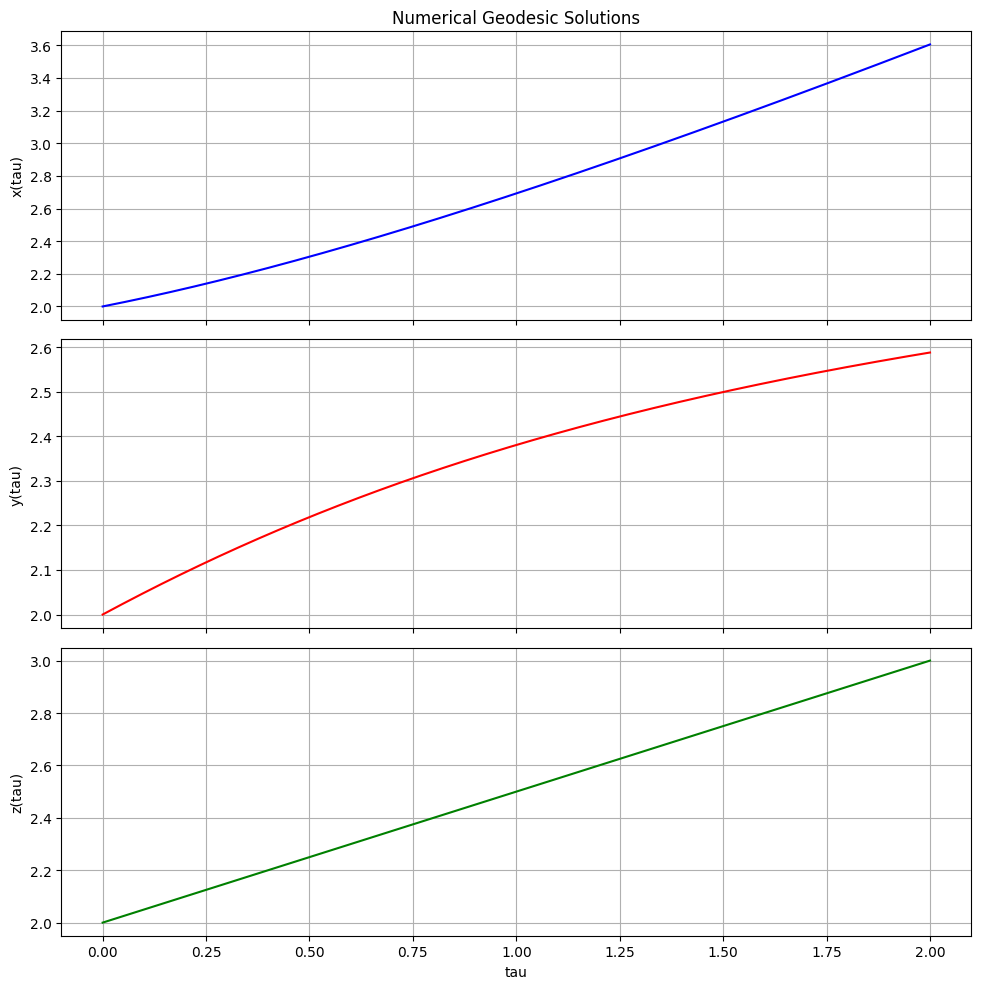

Numerical integration successful: True
Initial position: [2.0, 2.0, 2.0]
Initial velocity: [0.5, 0.5, 0.5]
Final position: [3.60555128 2.5880026  3.        ]


In [6]:
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# ======================================================
# 1. INITIAL CONDITIONS (CHANGE THESE VALUES)
# ======================================================

# Initial position: [x(0), y(0), z(0)]
initial_position = [2.0, 2.0, 2.0]  # <-- Change here

# Initial velocity: [dx/dtau(0), dy/dtau(0), dz/dtau(0)]
initial_velocity = [0.5, 0.5, 0.5]  # <-- Change here

# Parameter interval
tau_start = 0.0
tau_end = 2.0  # <-- Change the interval if needed
num_points = 1000

# ======================================================
# 2. PREPARE CHRISTOFFEL SYMBOLS FOR NUMERICAL EVALUATION
# ======================================================

# Convert the symbolic Christoffel symbols into numerical functions
Gamma_func = [
    [
        [
            sp.lambdify((x, y, z), Gamma[i][j][k], "numpy")
            for k in range(n)
        ]
        for j in range(n)
    ]
    for i in range(n)
]

# ======================================================
# 3. DEFINE THE GEODESIC SYSTEM
# ======================================================

# State vector:
# [x, y, z, dx/dtau, dy/dtau, dz/dtau]

def geodesic_system(tau, state):
    position = state[:n]
    velocity = state[n:]

    acceleration = np.zeros(n)

    # d²x^i/dtau² = - Gamma^i_jk (dx^j/dtau)(dx^k/dtau)
    for i in range(n):
        for j in range(n):
            for k in range(n):
                gamma_value = Gamma_func[i][j][k](*position)
                acceleration[i] -= (
                    float(gamma_value)
                    * velocity[j]
                    * velocity[k]
                )

    return np.concatenate((velocity, acceleration))

# ======================================================
# 4. SOLVE NUMERICALLY
# ======================================================

initial_state = initial_position + initial_velocity
tau_values = np.linspace(tau_start, tau_end, num_points)

solution = solve_ivp(
    geodesic_system,
    (tau_start, tau_end),
    initial_state,
    t_eval=tau_values,
    method="DOP853",
    rtol=1e-9,
    atol=1e-11
)

if not solution.success:
    raise RuntimeError(solution.message)

# Extract coordinate solutions
x_values = solution.y[0]
y_values = solution.y[1]
z_values = solution.y[2]

# ======================================================
# 5. PLOT x(tau), y(tau), z(tau)
# ======================================================

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

axes[0].plot(solution.t, x_values, color="blue")
axes[0].set_ylabel("x(tau)")
axes[0].set_title("Numerical Geodesic Solutions")
axes[0].grid(True)

axes[1].plot(solution.t, y_values, color="red")
axes[1].set_ylabel("y(tau)")
axes[1].grid(True)

axes[2].plot(solution.t, z_values, color="green")
axes[2].set_ylabel("z(tau)")
axes[2].set_xlabel("tau")
axes[2].grid(True)

plt.tight_layout()
plt.show()

print("Numerical integration successful:", solution.success)
print("Initial position:", initial_position)
print("Initial velocity:", initial_velocity)
print("Final position:", solution.y[:n, -1])


# Applying Physics-Informed Neural Network

## Single Run PINN (use the next one)

In [6]:
!pip install deepxde -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.4/195.4 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 6.3 MB/s eta 0:00:00


Compiling model...
'compile' took 0.005446 s

TRAINING DEEPXDE PINN
Training model...

Step      Train loss                                                                                    Test loss                                                                                     Test metric
0         [7.52e-02, 6.07e-02, 3.00e-02, 4.00e+00, 4.00e+00, 4.00e+00, 7.90e-02, 4.67e-02, 6.24e-04]    [7.56e-02, 6.02e-02, 3.01e-02, 4.00e+00, 4.00e+00, 4.00e+00, 7.90e-02, 4.67e-02, 6.24e-04]    []  
1000      [1.10e-03, 2.48e-04, 9.16e-05, 7.00e-06, 2.06e-06, 1.63e-06, 7.53e-04, 4.25e-04, 3.68e-04]    [1.10e-03, 2.44e-04, 9.19e-05, 7.00e-06, 2.06e-06, 1.63e-06, 7.53e-04, 4.25e-04, 3.68e-04]    []  
2000      [1.26e-04, 2.00e-06, 1.90e-05, 1.76e-08, 3.27e-11, 4.30e-11, 8.70e-09, 4.23e-07, 1.99e-08]    [1.19e-04, 1.98e-06, 1.87e-05, 1.76e-08, 3.14e-11, 4.46e-11, 8.70e-09, 4.23e-07, 1.99e-08]    []  
3000      [8.15e-05, 2.68e-06, 1.22e-05, 1.03e-08, 6.57e-11, 1.11e-11, 1.74e-08, 2.27e-07, 2.0

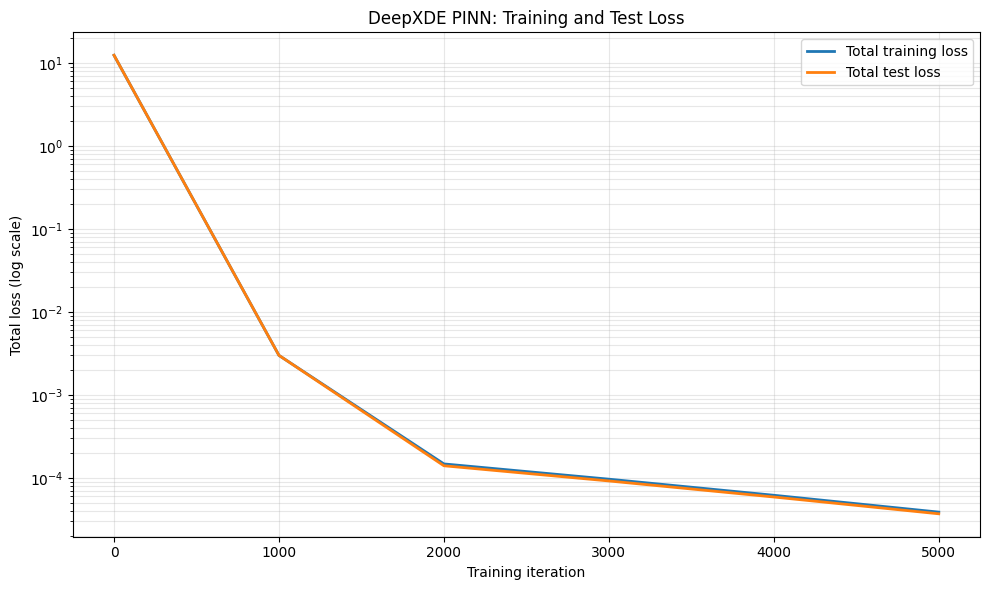

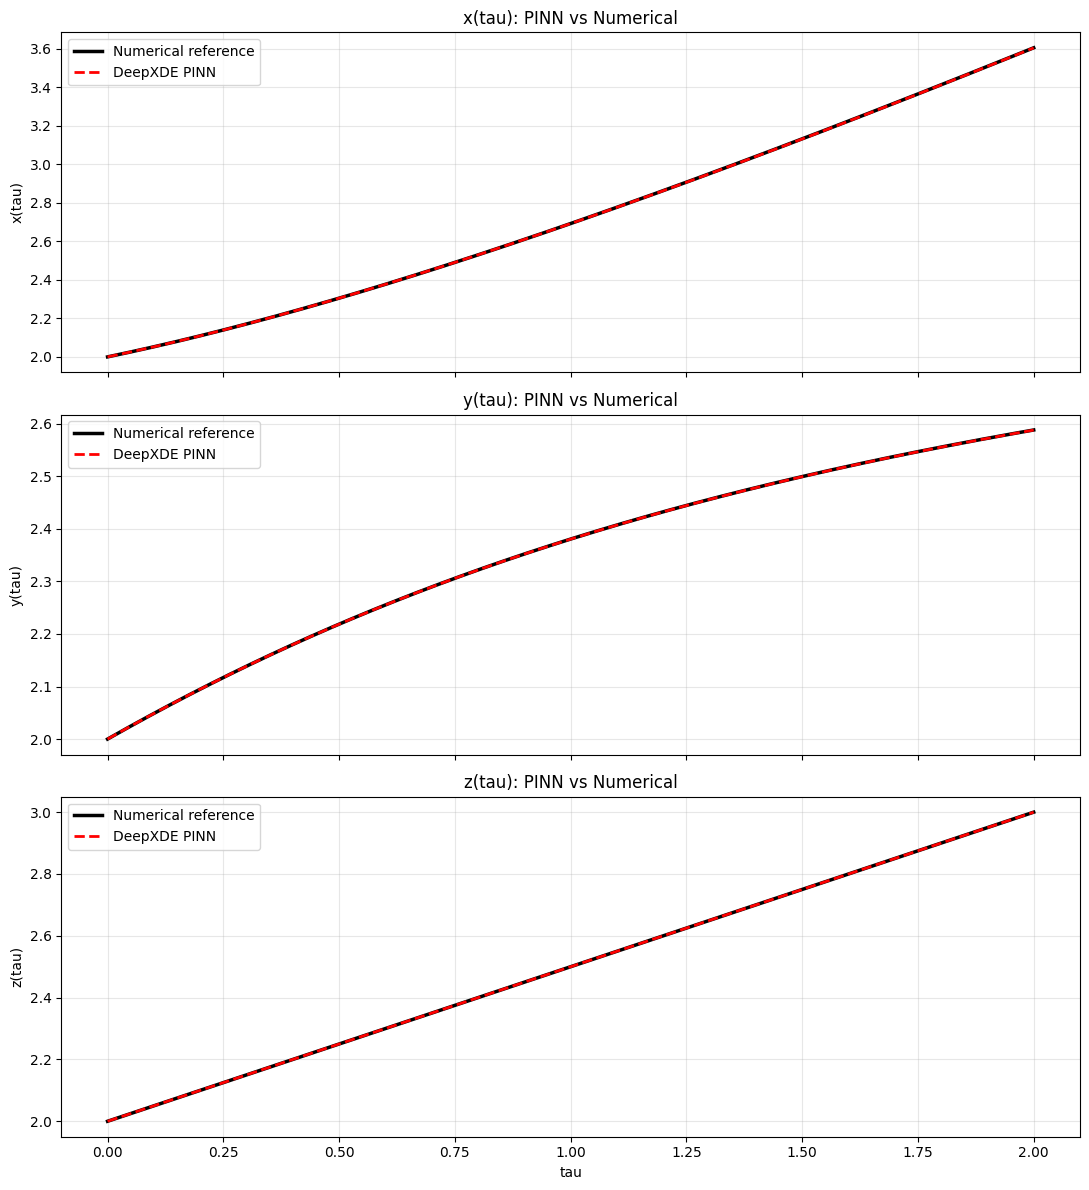

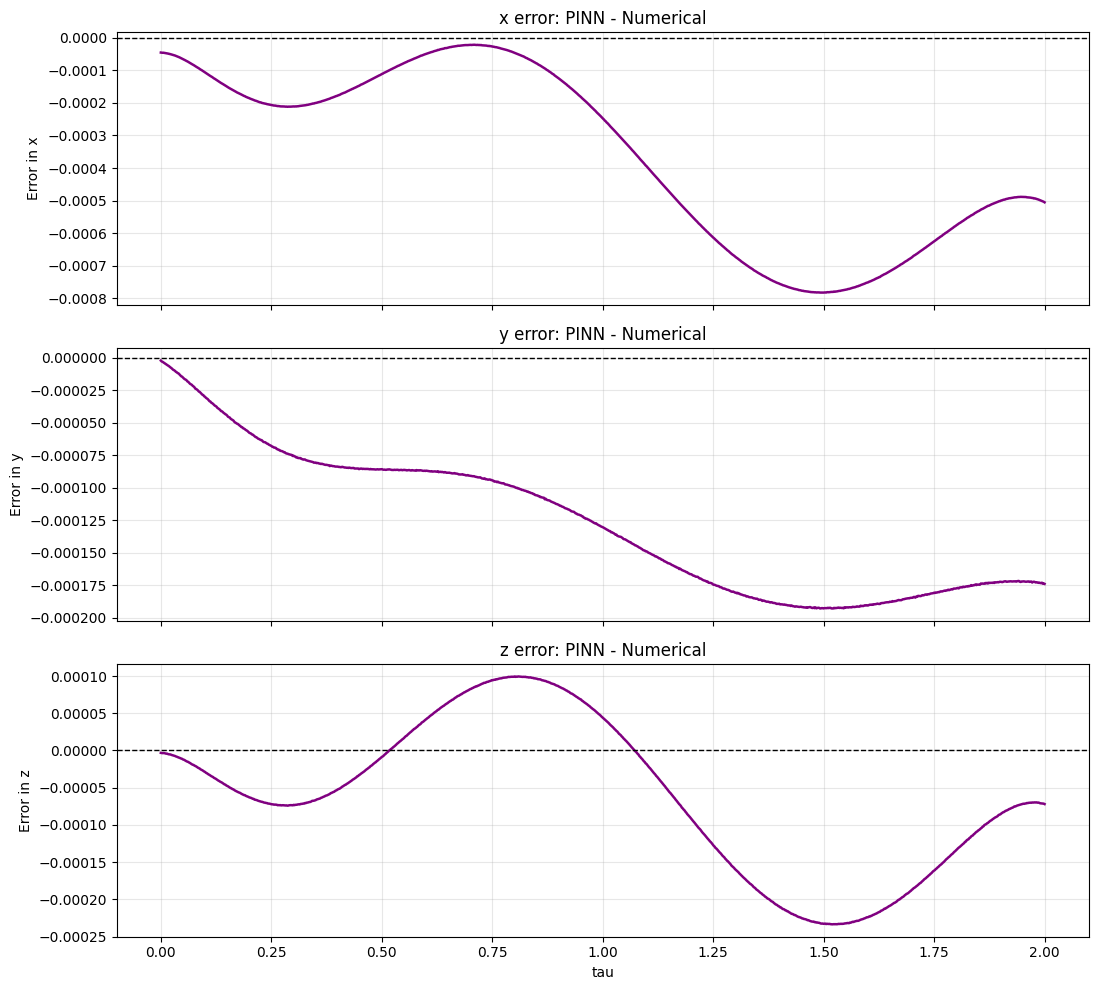


PINN VS NUMERICAL ERROR ANALYSIS

Coordinate: x
MAE  = 3.600824e-04
RMSE = 4.487092e-04
Maximum absolute error = 7.825358e-04

Coordinate: y
MAE  = 1.272503e-04
RMSE = 1.381718e-04
Maximum absolute error = 1.929001e-04

Coordinate: z
MAE  = 9.786370e-05
RMSE = 1.194867e-04
Maximum absolute error = 2.335070e-04

Initial position: [2. 2. 2.]
Initial velocity: [0.5 0.5 0.5]
Tau interval: (0.0, 2.0)
Numerical integration successful: True
Final numerical position: [3.60555128 2.5880026  3.        ]
Final PINN position: [3.605046  2.5878286 2.999928 ]

All calculations completed.


In [ ]:

# ================================================================
# DEEPXDE PINN vs NUMERICAL GEODESIC SOLUTION
# Metric: ds^2 = dx^2 + x^2 dy^2 + dz^2
# Three second-order equations; three neural-network outputs
# ================================================================

# If needed, install in a separate Google Colab cell:
# %pip install deepxde

import os
os.environ["DDE_BACKEND"] = "tensorflow"

import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ================================================================
# 1. INITIAL CONDITIONS AND SETTINGS
# ================================================================

# CHANGE INITIAL CONDITIONS HERE
initial_position = np.array([2.0, 2.0, 2.0], dtype=float)
initial_velocity = np.array([0.5, 0.5, 0.5], dtype=float)

# CHANGE THE PARAMETER INTERVAL HERE
tau_start = 0.0
tau_end = 2.0
num_points = 1000

# PINN training settings
num_domain = 2000
num_test = 1000
adam_iterations = 10000
#adam_iterations = 15000
learning_rate = 1e-3
use_lbfgs = False

# Four hidden layers with 64 neurons per layer
hidden_layers = [64, 64, 64, 64]
#hidden_layers = [128, 128, 128, 128]

initial_state = np.concatenate(
    [initial_position, initial_velocity]
)

if initial_state.shape != (6,):
    raise ValueError(
        "initial_position and initial_velocity must each "
        "contain exactly three values."
    )

if not np.all(np.isfinite(initial_state)):
    raise ValueError("Initial conditions must be finite.")

if tau_end <= tau_start:
    raise ValueError("tau_end must be greater than tau_start.")

# ================================================================
# 2. EXPLICIT SECOND-ORDER GEODESIC EQUATIONS
# ================================================================

# Metric:
# ds^2 = dx^2 + x^2 dy^2 + dz^2
#
# Geodesic equations:
#
# (1) -x(y'')^2 + x'' = 0
#
# (2) x*y'' + 2*x'*y'= 0
#
# (3) z'' = 0
#
# Equations (2) and (3) are the original equations multiplied
# by x and x*y, respectively, to avoid explicit divisions.
#
# Neural network outputs: [x, y, z]

def geodesic_pde(tau, Y):

    X = Y[:, 0:1]
    Ycoord = Y[:, 1:2]
    Z = Y[:, 2:3]

    # First derivatives
    dX = dde.grad.jacobian(Y, tau, i=0, j=0)
    dY = dde.grad.jacobian(Y, tau, i=1, j=0)
    #dZ = dde.grad.jacobian(Y, tau, i=2, j=0)

    # Second derivatives
    ddX = dde.grad.hessian(Y, tau, component=0, i=0, j=0)
    ddY = dde.grad.hessian(Y, tau, component=1, i=0, j=0)
    ddZ = dde.grad.hessian(Y, tau, component=2, i=0, j=0)

    # Explicit geodesic residuals
    eq1 = - X * dY**2 + ddX

    eq2 = X * ddY + 2.0 * dX * dY

    eq3 = ddZ

    return [eq1, eq2, eq3]


# ================================================================
# 3. INITIAL CONDITIONS
# ================================================================

geom = dde.geometry.TimeDomain(tau_start, tau_end)
initial_tau = np.array([[tau_start]])

ic_bcs = []

# Initial positions: x(tau_start), y(tau_start), z(tau_start)
for component in range(3):
    ic_bcs.append(
        dde.icbc.PointSetBC(
            initial_tau,
            np.array([[initial_position[component]]]),
            component=component
        )
    )

# Initial velocities are imposed through derivative operators.
# Use a boundary condition that applies only at tau_start.
for component in range(3):

    target_velocity = float(initial_velocity[component])

    def velocity_operator(inputs, outputs, X_boundary,
                          c=component, target=target_velocity):
        return (
            dde.grad.jacobian(outputs, inputs, i=c, j=0)
            - target
        )

    ic_bcs.append(
        dde.icbc.OperatorBC(
            geom,
            velocity_operator,
            lambda point, on_boundary:
                on_boundary and np.isclose(point[0], tau_start)
        )
    )

# ================================================================
# 4. BUILD AND TRAIN THE PINN
# ================================================================

data = dde.data.PDE(
    geom,
    geodesic_pde,
    ic_bcs,
    num_domain=num_domain,
    num_boundary=10,
    num_test=num_test
)

net = dde.nn.FNN(
    [1] + hidden_layers + [3],
    activation="tanh",
    kernel_initializer="Glorot uniform"
)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate)

print("=" * 65)
print("TRAINING DEEPXDE PINN")
print("=" * 65)

loss_history, train_state = model.train(
    iterations=adam_iterations,
    display_every=1000
)

if use_lbfgs:
    print("\nRefining with L-BFGS...")
    model.compile("L-BFGS")
    loss_history, train_state = model.train(
        display_every=1000
    )

print("\nPINN training completed.")

# ================================================================
# 5. TRAINING AND TEST LOSS
# ================================================================

steps = np.asarray(loss_history.steps)
train_loss = np.asarray(loss_history.loss_train, dtype=float)
test_loss = np.asarray(loss_history.loss_test, dtype=float)

plt.figure(figsize=(10, 6))

plt.semilogy(
    steps,
    np.maximum(np.sum(train_loss, axis=1), 1e-16),
    label="Total training loss",
    linewidth=2
)

if test_loss.ndim == 2 and test_loss.shape[0] == len(steps):
    plt.semilogy(
        steps,
        np.maximum(np.sum(test_loss, axis=1), 1e-16),
        label="Total test loss",
        linewidth=2
    )

plt.xlabel("Training iteration")
plt.ylabel("Total loss (log scale)")
plt.title("DeepXDE PINN: Training and Test Loss")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ================================================================
# 6. NUMERICAL REFERENCE SOLUTION
# ================================================================

# State vector:
# [x, y, z, dx/dtau, dy/dtau, dz/dtau]
#
# Original equations solved as a first-order system:
#
# (1) -x(y'')^2 + x'' = 0
#
# (2) x*y'' + 2*x'*y'= 0
#
# (3) z'' = 0

def numerical_geodesic(tau, state):

    X, Ycoord, Z, U, V, W = state

    # These coordinates are singular at X=0 or Ycoord=0.
    if abs(X) < 1e-8 or abs(Ycoord) < 1e-8:
        raise ValueError(
            "Trajectory reached or approached x=0 or y=0, "
            "where this coordinate chart is singular."
        )

    dX = U
    dY = V
    dZ = W

    dU = X * V**2
    dV = -2.0 * U * V / X
    dW = 0.0

    return [dX, dY, dZ, dU, dV, dW]


tau_values = np.linspace(tau_start, tau_end, num_points)

# Stop the integration before reaching a coordinate singularity.
def singularity_event(tau, state):
    return min(abs(state[0]), abs(state[1])) - 1e-6

singularity_event.terminal = True
singularity_event.direction = -1

numerical_solution = solve_ivp(
    numerical_geodesic,
    (tau_start, tau_end),
    initial_state,
    t_eval=tau_values,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
    events=singularity_event
)

if not numerical_solution.success:
    raise RuntimeError(numerical_solution.message)

if len(numerical_solution.t) < num_points:
    raise RuntimeError(
        "Numerical integration stopped before tau_end because "
        "the trajectory approached x=0 or y=0. Use a shorter "
        "interval or a nonsingular coordinate chart."
    )

actual_x, actual_y, actual_z = numerical_solution.y[:3]

# ================================================================
# 7. PINN PREDICTIONS
# ================================================================

pinn_prediction = model.predict(tau_values.reshape(-1, 1))

if not np.all(np.isfinite(pinn_prediction)):
    raise FloatingPointError(
        "PINN predictions contain non-finite values. "
        "Check the training loss and coordinate range."
    )

pinn_x = pinn_prediction[:, 0]
pinn_y = pinn_prediction[:, 1]
pinn_z = pinn_prediction[:, 2]

# ================================================================
# 8. PINN VS NUMERICAL SOLUTION
# ================================================================

actual = [actual_x, actual_y, actual_z]
predicted = [pinn_x, pinn_y, pinn_z]
names = ["x", "y", "z"]

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(
        tau_values, actual[i],
        "k-", linewidth=2.5,
        label="Numerical reference"
    )
    ax.plot(
        tau_values, predicted[i],
        "r--", linewidth=2,
        label="DeepXDE PINN"
    )

    ax.set_ylabel(f"{names[i]}(tau)")
    ax.set_title(f"{names[i]}(tau): PINN vs Numerical")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("tau")
plt.tight_layout()
plt.show()

# ================================================================
# 9. ERROR PLOTS
# ================================================================

errors = [predicted[i] - actual[i] for i in range(3)]

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(tau_values, errors[i], color="purple", linewidth=1.8)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_ylabel(f"Error in {names[i]}")
    ax.set_title(f"{names[i]} error: PINN - Numerical")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("tau")
plt.tight_layout()
plt.show()

# ================================================================
# 10. ERROR METRICS AND FINAL SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("PINN VS NUMERICAL ERROR ANALYSIS")
print("=" * 65)

for name, error in zip(names, errors):
    print(f"\nCoordinate: {name}")
    print(f"MAE  = {np.mean(np.abs(error)):.6e}")
    print(f"RMSE = {np.sqrt(np.mean(error**2)):.6e}")
    print(f"Maximum absolute error = {np.max(np.abs(error)):.6e}")

print("\nInitial position:", initial_position)
print("Initial velocity:", initial_velocity)
print("Tau interval:", (tau_start, tau_end))
print("Numerical integration successful:", numerical_solution.success)
print("Final numerical position:", numerical_solution.y[:3, -1])
print("Final PINN position:", pinn_prediction[-1, :])
print("\nAll calculations completed.")


# Box plot and Violin plot of errors

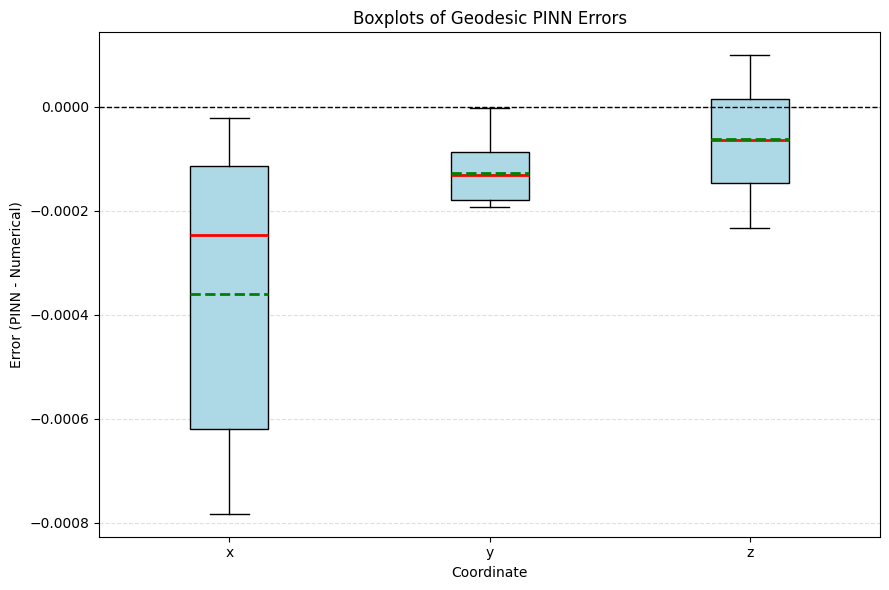

In [ ]:
# ================================================================
# 10. BOXPLOTS OF ERRORS
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

# Errors are defined as PINN - Numerical
errors = [
    pinn_x - actual_x,
    pinn_y - actual_y,
    pinn_z - actual_z
]

names = ["x", "y", "z"]

plt.figure(figsize=(9, 6))

plt.boxplot(
    errors,
    tick_labels=names,  # Use labels=names for older Matplotlib versions
    patch_artist=True,
    showmeans=True,
    meanline=True,
    showfliers=True,
    boxprops=dict(facecolor="lightblue", color="black"),
    medianprops=dict(color="red", linewidth=2),
    meanprops=dict(color="green", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(
        marker="o",
        markerfacecolor="orange",
        markersize=4,
        markeredgecolor="black"
    )
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("Coordinate")
plt.ylabel("Error (PINN - Numerical)")
plt.title("Boxplots of Geodesic PINN Errors")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

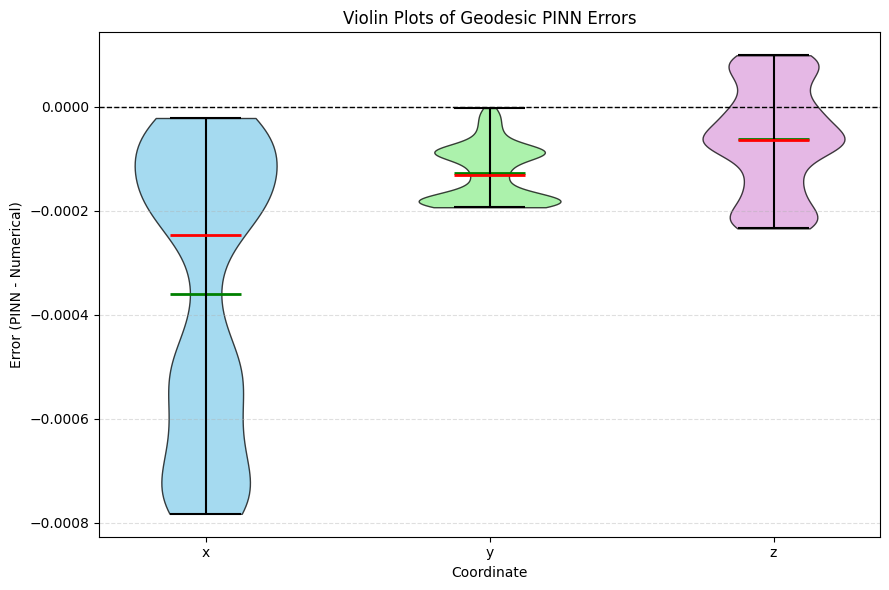

In [ ]:
# ================================================================
# 11. VIOLIN PLOTS OF ERRORS
# ================================================================

plt.figure(figsize=(9, 6))

violin = plt.violinplot(
    errors,
    showmeans=True,
    showmedians=True,
    showextrema=True
)

# Customize violin body colors
colors = ["skyblue", "lightgreen", "plum"]

for body, color in zip(violin["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.75)

# Customize summary lines
violin["cmeans"].set_color("green")
violin["cmeans"].set_linewidth(2)

violin["cmedians"].set_color("red")
violin["cmedians"].set_linewidth(2)

violin["cbars"].set_color("black")
violin["cmins"].set_color("black")
violin["cmaxes"].set_color("black")

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xticks([1, 2, 3], names)
plt.xlabel("Coordinate")
plt.ylabel("Error (PINN - Numerical)")
plt.title("Violin Plots of Geodesic PINN Errors")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Loss components

Meaning

1-3

Residuals of the three second-order geodesic equations

4-6

Initial position conditions:
$x(0),y(0),z(0)$

7-9

Initial velocity conditions:
$x'(0),y'(0),z'(0)$

# Random seed multiple run PINN for geodesic equations

In [8]:
!pip install deepxde -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.4/195.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 7.3 MB/s eta 0:00:00


Using backend: tensorflow
Other supported backends: tensorflow.compat.v1, pytorch, jax, paddle.
paddle supports more examples now and is recommended.
Enable just-in-time compilation with XLA.



MULTI-SEED DEEPXDE PINN EXPERIMENT
Number of runs: 10
Random seeds: [1234, 1235, 1236, 1237, 1238, 1239, 1240, 1241, 1242, 1243]
Network architecture: [1, 64, 64, 64, 64, 3]
Training iterations per run: 10000
Computing a single numerical reference for all runs.

Run 1/10 | Seed = 1234
Compiling model...
'compile' took 0.027706 s


Training run with random seed = 1234
Training model...

Step      Train loss                                                                                    Test loss                                                                                     Test metric
0         [6.78e-05, 7.33e-05, 3.92e-03, 4.00e+00, 4.00e+00, 4.00e+00, 2.12e-01, 2.93e-01, 4.08e-01]    [6.82e-05, 7.34e-05, 3.94e-03, 4.00e+00, 4.00e+00, 4.00e+00, 2.12e-01, 2.93e-01, 4.08e-01]    []  
1000      [9.04e-05, 1.49e-05, 1.73e-05, 3.20e-12, 8.88e-10, 3.38e-09, 1.66e-06, 4.95e-08, 6.45e-07]    [8.60e-05, 1.46e-05, 1.69e-05, 4.11e-12, 8.88e-10, 3.36e-09, 1.66e-06, 4.95e-08, 6.46e-07]    

Seed 1238 completed | Overall RMSE = 3.187116e-04

Run 6/10 | Seed = 1239
Compiling model...
'compile' took 0.006917 s


Training run with random seed = 1239
Training model...

Step      Train loss                                                                                    Test loss                                                                                     Test metric
0         [6.78e-05, 7.34e-05, 3.92e-03, 4.00e+00, 4.00e+00, 4.00e+00, 2.12e-01, 2.93e-01, 4.08e-01]    [6.82e-05, 7.34e-05, 3.94e-03, 4.00e+00, 4.00e+00, 4.00e+00, 2.12e-01, 2.93e-01, 4.08e-01]    []  
1000      [8.67e-05, 1.54e-05, 1.71e-05, 1.56e-07, 5.22e-09, 1.70e-08, 3.15e-06, 3.04e-06, 1.12e-06]    [8.31e-05, 1.50e-05, 1.68e-05, 1.56e-07, 5.20e-09, 1.70e-08, 3.15e-06, 3.04e-06, 1.12e-06]    []  
2000      [2.22e-04, 8.61e-05, 1.99e-05, 3.47e-06, 9.82e-07, 1.47e-06, 1.79e-04, 1.12e-04, 8.48e-05]    [2.22e-04, 8.45e-05, 1.98e-05, 3.47e-06, 9.83e-07, 1.47e-06, 1.79e-04, 1.12e-04, 8.48e-05]    []  
3000

Seed 1239 completed | Overall RMSE = 7.385974e-03

Run 7/10 | Seed = 1240
Compiling model...
'compile' took 0.006420 s


Training run with random seed = 1240
Training model...

Step      Train loss                                                                                    Test loss                                                                                     Test metric
0         [6.78e-05, 7.35e-05, 3.92e-03, 4.00e+00, 4.00e+00, 4.00e+00, 2.12e-01, 2.93e-01, 4.08e-01]    [6.82e-05, 7.34e-05, 3.94e-03, 4.00e+00, 4.00e+00, 4.00e+00, 2.12e-01, 2.93e-01, 4.08e-01]    []  
1000      [8.74e-05, 1.40e-05, 1.72e-05, 1.64e-08, 6.39e-10, 2.71e-10, 6.34e-08, 3.77e-07, 3.07e-08]    [8.36e-05, 1.38e-05, 1.68e-05, 1.64e-08, 6.27e-10, 2.63e-10, 6.34e-08, 3.77e-07, 3.06e-08]    []  
2000      [5.90e-05, 7.55e-06, 9.84e-06, 1.32e-08, 8.43e-11, 8.65e-11, 1.47e-08, 3.06e-07, 1.34e-08]    [5.68e-05, 7.39e-06, 9.44e-06, 1.33e-08, 7.99e-11, 8.21e-11, 1.47e-08, 3.06e-07, 1.34e-08]    []  
3000

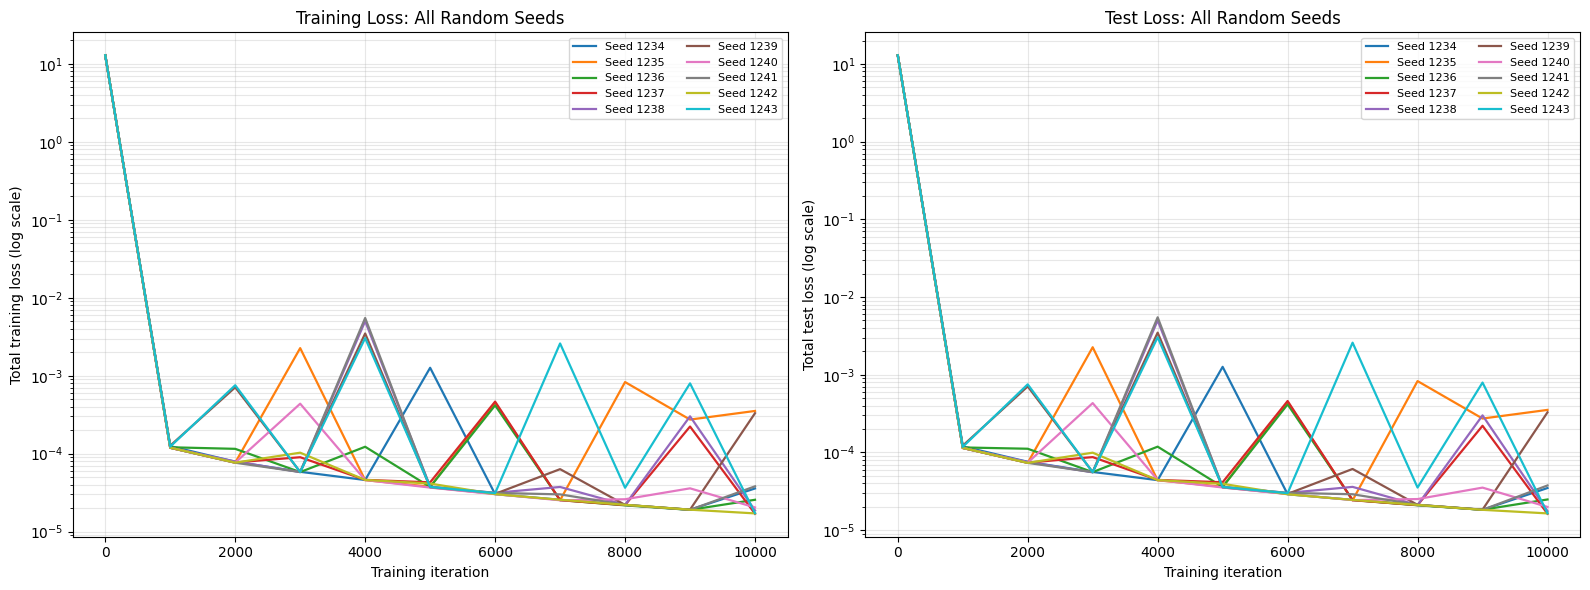

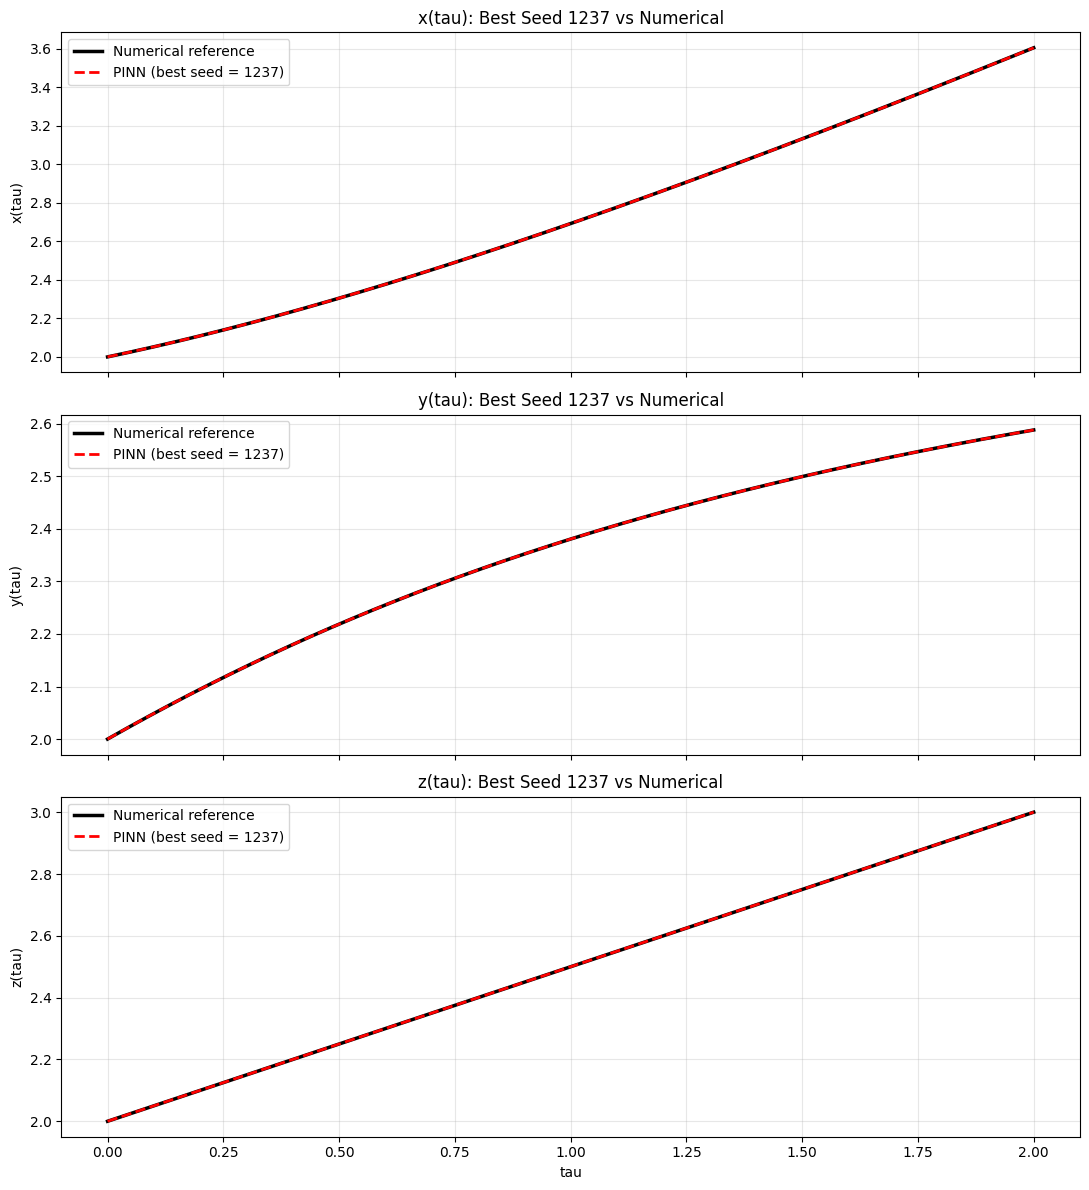

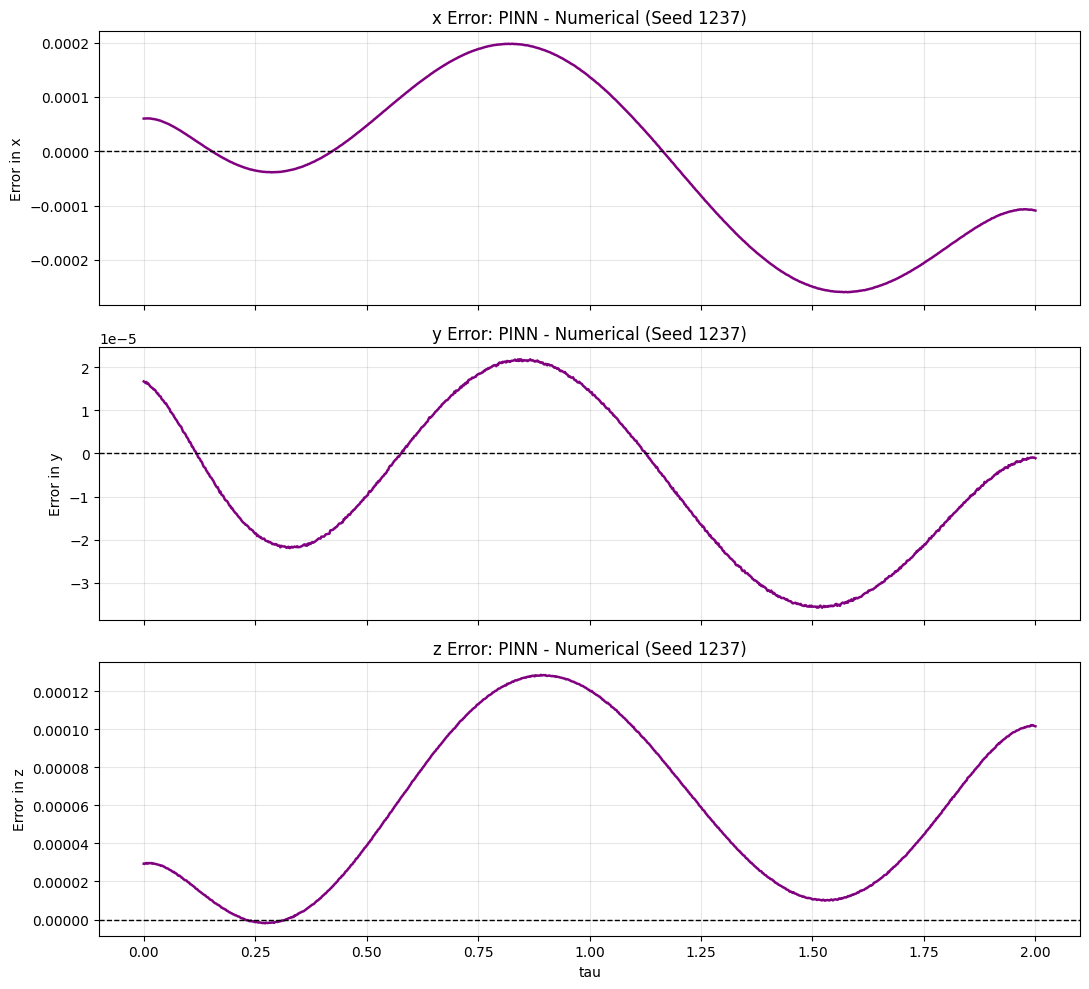

/tmp/ipykernel_829/7252416.py:471: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(
/tmp/ipykernel_829/7252416.py:471: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(
/tmp/ipykernel_829/7252416.py:471: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


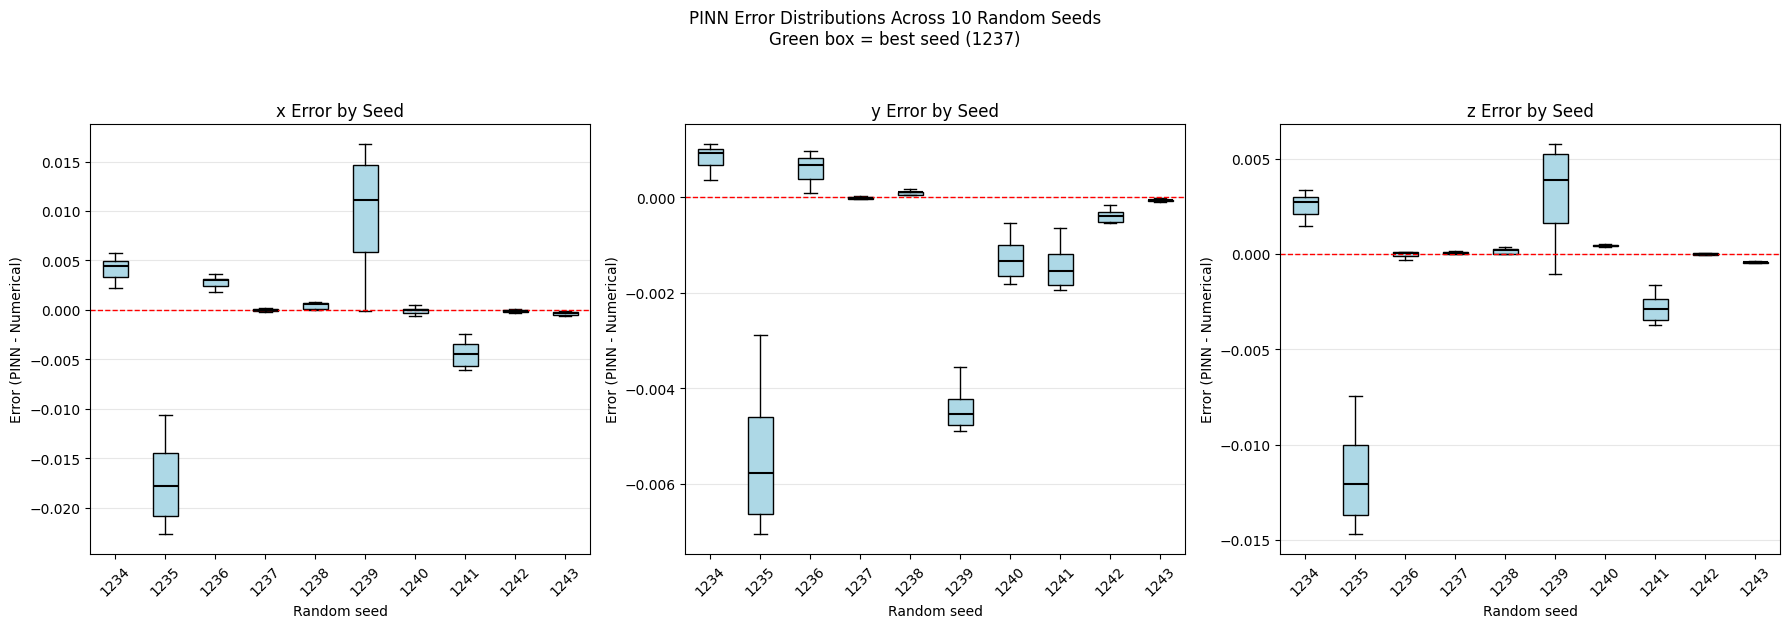

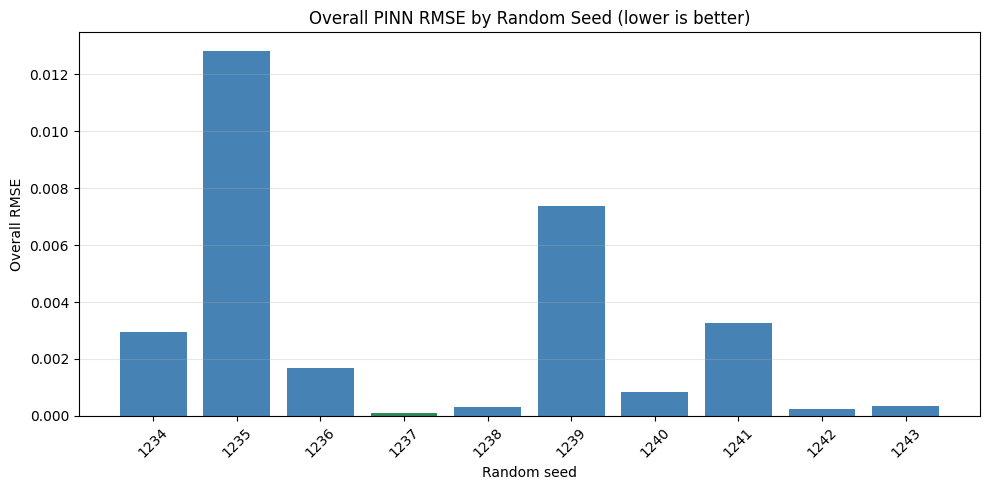


ERROR METRICS FOR ALL RANDOM SEEDS
    Seed   Coordinate             MAE            RMSE           MaxAE    Overall RMSE
----------------------------------------------------------------------------------------------------
    1234            x    4.183179e-03    4.300472e-03    5.706754e-03    2.953427e-03
    1234            y    8.473683e-04    8.753581e-04    1.128752e-03    2.953427e-03
    1234            z    2.570851e-03    2.628284e-03    3.375769e-03    2.953427e-03
----------------------------------------------------------------------------------------------------
    1235            x    1.750361e-02    1.786610e-02    2.269486e-02    1.283001e-02
    1235            y    5.534854e-03    5.664994e-03    7.066648e-03    1.283001e-02
    1235            z    1.174880e-02    1.193891e-02    1.470613e-02    1.283001e-02
----------------------------------------------------------------------------------------------------
    1236            x    2.806562e-03    2.854429e-03    3.

In [9]:

# ================================================================
# DEEPXDE PINN vs NUMERICAL GEODESIC SOLUTION
# Multiple random-seed experiments with:
# 1. Best-seed solution comparison
# 2. Training/test loss curves for all seeds
# 3. Error box plots labelled by seed
# 4. MAE, RMSE, and maximum absolute error for every seed
#
# Metric: ds^2 = dx^2 + x^2 dy^2 + dz^2
# Network outputs: [x, y, z]
# ================================================================
import time

t1 = time.perf_counter()


import os
os.environ["DDE_BACKEND"] = "tensorflow"

import random
import numpy as np
import matplotlib.pyplot as plt
import deepxde as dde
import tensorflow as tf
from scipy.integrate import solve_ivp

# ================================================================
# 1. INITIAL CONDITIONS AND SETTINGS
# ================================================================

# Initial conditions
initial_position = np.array([2.0, 2.0, 2.0], dtype=float)
initial_velocity = np.array([0.5, 0.5, 0.5], dtype=float)

# Parameter interval
tau_start = 0.0
tau_end = 2.0
num_points = 1000

# ------------------------------------------------
# MULTI-SEED SETTINGS: CHANGE THESE AS REQUIRED
# ------------------------------------------------
num_runs = 10              # Number of independent experiments
base_seed = 1234           # Seeds will be 1234, 1235, ..., 1243

# PINN training settings (kept identical for every run)
num_domain = 2000
num_boundary = 10
num_test = 1000
adam_iterations = 10000
learning_rate = 1e-3
use_lbfgs = False

# Same network configuration for every seed
hidden_layers = [64, 64, 64, 64]
activation = "tanh"
initializer = "Glorot uniform"

# Seeds are different, but the network configuration is unchanged
random_seeds = [base_seed + i for i in range(num_runs)]

initial_state = np.concatenate(
    [initial_position, initial_velocity]
)

if initial_state.shape != (6,):
    raise ValueError("Initial position and velocity must each contain 3 values.")

if not np.all(np.isfinite(initial_state)):
    raise ValueError("Initial conditions must be finite.")

if tau_end <= tau_start:
    raise ValueError("tau_end must be greater than tau_start.")

if num_runs < 1:
    raise ValueError("num_runs must be at least 1.")

# ================================================================
# 2. GEODESIC EQUATIONS
# ================================================================

def geodesic_pde(tau, Y):

    X = Y[:, 0:1]

    dX = dde.grad.jacobian(Y, tau, i=0, j=0)
    dY = dde.grad.jacobian(Y, tau, i=1, j=0)

    ddX = dde.grad.hessian(Y, tau, component=0, i=0, j=0)
    ddY = dde.grad.hessian(Y, tau, component=1, i=0, j=0)
    ddZ = dde.grad.hessian(Y, tau, component=2, i=0, j=0)

    eq1 = -X * dY**2 + ddX
    eq2 = X * ddY + 2.0 * dX * dY
    eq3 = ddZ

    return [eq1, eq2, eq3]


# ================================================================
# 3. NUMERICAL REFERENCE SOLUTION (COMPUTE ONCE)
# ================================================================

def numerical_geodesic(tau, state):

    X, Ycoord, Z, U, V, W = state

    # Retained from the original script
    if abs(X) < 1e-8 or abs(Ycoord) < 1e-8:
        raise ValueError(
            "Trajectory reached or approached x=0 or y=0."
        )

    dX = U
    dY = V
    dZ = W

    dU = X * V**2
    dV = -2.0 * U * V / X
    dW = 0.0

    return [dX, dY, dZ, dU, dV, dW]


tau_values = np.linspace(tau_start, tau_end, num_points)

def singularity_event(tau, state):
    return min(abs(state[0]), abs(state[1])) - 1e-6

singularity_event.terminal = True
singularity_event.direction = -1

numerical_solution = solve_ivp(
    numerical_geodesic,
    (tau_start, tau_end),
    initial_state,
    t_eval=tau_values,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
    events=singularity_event
)

if not numerical_solution.success:
    raise RuntimeError(numerical_solution.message)

if len(numerical_solution.t) != num_points:
    raise RuntimeError(
        "Numerical integration did not reach the complete interval. "
        "Use a shorter interval or check the trajectory."
    )

# Shape: (num_points, 3)
actual = numerical_solution.y[:3, :].T
coordinate_names = ["x", "y", "z"]

print("=" * 75)
print("MULTI-SEED DEEPXDE PINN EXPERIMENT")
print("=" * 75)
print(f"Number of runs: {num_runs}")
print(f"Random seeds: {random_seeds}")
print(f"Network architecture: {[1] + hidden_layers + [3]}")
print(f"Training iterations per run: {adam_iterations}")
print("Computing a single numerical reference for all runs.")


# ================================================================
# 4. HELPER: CREATE AND TRAIN ONE PINN
# ================================================================

def train_one_seed(seed):

    # Set all relevant random seeds before creating the network.
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    dde.config.set_random_seed(seed)

    # Create fresh data, network, and model for each run.
    geom = dde.geometry.TimeDomain(tau_start, tau_end)
    initial_tau = np.array([[tau_start]])

    ic_bcs = []

    # Initial positions
    for component in range(3):
        ic_bcs.append(
            dde.icbc.PointSetBC(
                initial_tau,
                np.array([[initial_position[component]]]),
                component=component
            )
        )

    # Initial velocities
    for component in range(3):

        target_velocity = float(initial_velocity[component])

        def velocity_operator(
            inputs, outputs, X_boundary,
            c=component, target=target_velocity
        ):
            return (
                dde.grad.jacobian(outputs, inputs, i=c, j=0)
                - target
            )

        ic_bcs.append(
            dde.icbc.OperatorBC(
                geom,
                velocity_operator,
                lambda point, on_boundary:
                    on_boundary and np.isclose(point[0], tau_start)
            )
        )

    data = dde.data.PDE(
        geom,
        geodesic_pde,
        ic_bcs,
        num_domain=num_domain,
        num_boundary=num_boundary,
        num_test=num_test
    )

    net = dde.nn.FNN(
        [1] + hidden_layers + [3],
        activation=activation,
        kernel_initializer=initializer
    )

    model = dde.Model(data, net)
    model.compile("adam", lr=learning_rate)

    print(f"\n{'=' * 65}")
    print(f"Training run with random seed = {seed}")
    print(f"{'=' * 65}")

    loss_history, train_state = model.train(
        iterations=adam_iterations,
        display_every=1000
    )

    # Save Adam loss history before optional L-BFGS refinement.
    adam_history = loss_history

    if use_lbfgs:
        print(f"Seed {seed}: refining with L-BFGS...")
        model.compile("L-BFGS")
        loss_history, train_state = model.train(
            display_every=1000
        )

    # Predict at the same points as the numerical solution.
    prediction = model.predict(tau_values.reshape(-1, 1))

    if not np.all(np.isfinite(prediction)):
        raise FloatingPointError(
            f"Non-finite predictions for seed {seed}."
        )

    # Errors are signed: PINN prediction minus reference.
    errors = prediction - actual

    # Overall RMSE gives equal weight to all 3 coordinates
    # and all sampled tau points.
    overall_rmse = float(np.sqrt(np.mean(errors**2)))

    metrics = {}

    for j, name in enumerate(coordinate_names):
        e = errors[:, j]
        metrics[name] = {
            "MAE": float(np.mean(np.abs(e))),
            "RMSE": float(np.sqrt(np.mean(e**2))),
            "MaxAE": float(np.max(np.abs(e)))
        }

    # Preserve the complete Adam history for comparable loss plots.
    # This keeps the displayed iterations on the same scale.
    steps = np.asarray(adam_history.steps)
    train_loss = np.asarray(adam_history.loss_train, dtype=float)
    test_loss = np.asarray(adam_history.loss_test, dtype=float)

    return {
        "seed": seed,
        "model": model,
        "prediction": prediction,
        "errors": errors,
        "overall_rmse": overall_rmse,
        "metrics": metrics,
        "steps": steps,
        "train_loss": train_loss,
        "test_loss": test_loss
    }


# ================================================================
# 5. RUN ALL RANDOM SEEDS
# ================================================================

results = []

for run_index, seed in enumerate(random_seeds, start=1):

    print(f"\nRun {run_index}/{num_runs} | Seed = {seed}")

    result = train_one_seed(seed)
    results.append(result)

    print(
        f"Seed {seed} completed | "
        f"Overall RMSE = {result['overall_rmse']:.6e}"
    )


# ================================================================
# 6. SELECT THE BEST SEED
# ================================================================

best_result = min(results, key=lambda result: result["overall_rmse"])

best_seed = best_result["seed"]
best_prediction = best_result["prediction"]
best_errors = best_result["errors"]

print("\n" + "=" * 75)
print("BEST-SEED SELECTION")
print("=" * 75)
print(f"Best seed: {best_seed}")
print(f"Best overall RMSE: {best_result['overall_rmse']:.6e}")
print("Selection criterion: lowest overall RMSE against numerical reference.")


# ================================================================
# 7. TRAINING AND TEST LOSS FOR ALL SEEDS
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for result in results:

    seed = result["seed"]
    steps = result["steps"]
    train_loss = result["train_loss"]
    test_loss = result["test_loss"]

    # Sum all PDE and boundary-condition loss components.
    total_train_loss = np.sum(train_loss, axis=1)

    axes[0].semilogy(
        steps,
        np.maximum(total_train_loss, 1e-16),
        linewidth=1.6,
        label=f"Seed {seed}"
    )

    if (
        test_loss.ndim == 2
        and test_loss.shape[0] == len(steps)
        and test_loss.shape[1] > 0
    ):
        total_test_loss = np.sum(test_loss, axis=1)

        axes[1].semilogy(
            steps,
            np.maximum(total_test_loss, 1e-16),
            linewidth=1.6,
            label=f"Seed {seed}"
        )

axes[0].set_title("Training Loss: All Random Seeds")
axes[0].set_xlabel("Training iteration")
axes[0].set_ylabel("Total training loss (log scale)")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8, ncol=2)

axes[1].set_title("Test Loss: All Random Seeds")
axes[1].set_xlabel("Training iteration")
axes[1].set_ylabel("Total test loss (log scale)")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()


# ================================================================
# 8. BEST-SEED PINN VS NUMERICAL SOLUTION
# ================================================================

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for j, ax in enumerate(axes):

    ax.plot(
        tau_values,
        actual[:, j],
        "k-",
        linewidth=2.5,
        label="Numerical reference"
    )

    ax.plot(
        tau_values,
        best_prediction[:, j],
        "r--",
        linewidth=2,
        label=f"PINN (best seed = {best_seed})"
    )

    ax.set_ylabel(f"{coordinate_names[j]}(tau)")
    ax.set_title(
        f"{coordinate_names[j]}(tau): Best Seed {best_seed} vs Numerical"
    )
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("tau")
plt.tight_layout()
plt.show()


# ================================================================
# 9. BEST-SEED ERROR VS TAU
# ================================================================

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

for j, ax in enumerate(axes):

    ax.plot(
        tau_values,
        best_errors[:, j],
        color="purple",
        linewidth=1.8
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_ylabel(f"Error in {coordinate_names[j]}")
    ax.set_title(
        f"{coordinate_names[j]} Error: PINN - Numerical "
        f"(Seed {best_seed})"
    )
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("tau")
plt.tight_layout()
plt.show()


# ================================================================
# 10. ERROR BOXPLOTS FOR EACH SEED
# ================================================================

# Each subplot represents a coordinate.
# Each box corresponds to a different random seed.
# Signed errors are used: PINN prediction minus numerical reference.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

seed_labels = [str(result["seed"]) for result in results]

for j, ax in enumerate(axes):

    errors_by_seed = [
        result["errors"][:, j] for result in results
    ]

    box = ax.boxplot(
        errors_by_seed,
        labels=seed_labels,
        patch_artist=True,
        showfliers=True,
        medianprops={"color": "black", "linewidth": 1.5}
    )

    for patch, result in zip(box["boxes"], results):
        if result["seed"] == best_seed:
            patch.set_facecolor("lightgreen")
        else:
            patch.set_facecolor("lightblue")

    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"{coordinate_names[j]} Error by Seed")
    ax.set_xlabel("Random seed")
    ax.set_ylabel("Error (PINN - Numerical)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    f"PINN Error Distributions Across {num_runs} Random Seeds\n"
    f"Green box = best seed ({best_seed})",
    y=1.04
)
plt.tight_layout()
plt.show()


# ================================================================
# 11. OVERALL RMSE COMPARISON ACROSS SEEDS
# ================================================================

fig, ax = plt.subplots(figsize=(10, 5))

bar_colors = [
    "seagreen" if result["seed"] == best_seed else "steelblue"
    for result in results
]

ax.bar(
    seed_labels,
    [result["overall_rmse"] for result in results],
    color=bar_colors
)

ax.set_xlabel("Random seed")
ax.set_ylabel("Overall RMSE")
ax.set_title("Overall PINN RMSE by Random Seed (lower is better)")
ax.grid(True, axis="y", alpha=0.3)
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# ================================================================
# 12. ERROR METRICS FOR EVERY SEED
# ================================================================

print("\n" + "=" * 100)
print("ERROR METRICS FOR ALL RANDOM SEEDS")
print("=" * 100)

print(
    f"{'Seed':>8} {'Coordinate':>12} {'MAE':>15} "
    f"{'RMSE':>15} {'MaxAE':>15} {'Overall RMSE':>15}"
)
print("-" * 100)

for result in results:

    for name in coordinate_names:

        m = result["metrics"][name]

        print(
            f"{result['seed']:>8} "
            f"{name:>12} "
            f"{m['MAE']:>15.6e} "
            f"{m['RMSE']:>15.6e} "
            f"{m['MaxAE']:>15.6e} "
            f"{result['overall_rmse']:>15.6e}"
        )

    print("-" * 100)


# ================================================================
# 13. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("FINAL SUMMARY")
print("=" * 75)

print(f"Number of runs: {num_runs}")
print(f"Seeds used: {random_seeds}")
print(f"Best seed: {best_seed}")
print(f"Best overall RMSE: {best_result['overall_rmse']:.6e}")

print("\nBest-seed coordinate metrics:")

for name in coordinate_names:

    m = best_result["metrics"][name]

    print(
        f"{name}: MAE = {m['MAE']:.6e}, "
        f"RMSE = {m['RMSE']:.6e}, "
        f"MaxAE = {m['MaxAE']:.6e}"
    )

print("\nInitial position:", initial_position)
print("Initial velocity:", initial_velocity)
print("Tau interval:", (tau_start, tau_end))
print("Final numerical position:", actual[-1])
print("Final best-seed PINN position:", best_prediction[-1])
t2 = time.perf_counter()

print("Time Taken =", t2 - t1, "seconds")
print("\nAll random-seed experiments and plots completed.")


# Interactive visualization of geodesic paths from a certain point of a 3d spatial metric ✅

In [7]:

# ============================================================
# INTERACTIVE GEODESIC VISUALIZATION FOR A 3D METRIC
# Google Colab / Jupyter Notebook
#
# Define g and coords before running this cell.
#
# g     : 3x3 SymPy metric matrix
# coords: (x, y, z)
#
# No induced metric and no fixed time coordinate.
# ============================================================

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display
from scipy.integrate import solve_ivp

# ============================================================
# 1. SETTINGS
# ============================================================

N_theta = 15
N_phi = 30

N_STEPS = 100
RTOL = 1e-7
ATOL = 1e-9

dim = 3

# ============================================================
# 2. VALIDATE THE 3D METRIC
# ============================================================

if not isinstance(g, sp.MatrixBase):
    raise TypeError("g must be a SymPy Matrix.")

if g.shape != (3, 3):
    raise ValueError("g must be a 3x3 matrix.")

if len(coords) != 3:
    raise ValueError("coords must contain exactly three coordinates.")

coords = tuple(coords)

if not all(
    sp.simplify(g[i, j] - g[j, i]) == 0
    for i in range(3)
    for j in range(3)
):
    raise ValueError("The metric must be symmetric.")

# Simplify the metric directly.
g = sp.simplify(g)

# Inverse metric
g_inv = sp.simplify(g.inv())

print("Coordinates:", coords)
print("\n3D Metric:")
sp.pprint(g)

print("\nInverse Metric:")
sp.pprint(g_inv)

# ============================================================
# 3. CHRISTOFFEL SYMBOLS
# ============================================================

# Gamma[i][j][k] = Gamma^i_{jk}

Gamma = [
    [
        [sp.S.Zero for k in range(dim)]
        for j in range(dim)
    ]
    for i in range(dim)
]

for i in range(dim):
    for j in range(dim):
        for k in range(dim):

            Gamma[i][j][k] = sp.simplify(
                sp.Rational(1, 2) * sum(
                    g_inv[i, l] * (
                        sp.diff(g[l, j], coords[k])
                        + sp.diff(g[l, k], coords[j])
                        - sp.diff(g[j, k], coords[l])
                    )
                    for l in range(dim)
                )
            )

print("\nNonzero Christoffel symbols:")

for i in range(dim):
    for j in range(dim):
        for k in range(dim):
            if Gamma[i][j][k] != 0:
                print(
                    f"Gamma^{i}_{{{j}{k}}} =",
                    Gamma[i][j][k]
                )

# ============================================================
# 4. NUMERICAL FUNCTIONS
# ============================================================

Gamma_func = [
    [
        [
            sp.lambdify(
                coords,
                Gamma[i][j][k],
                modules="numpy"
            )
            for k in range(dim)
        ]
        for j in range(dim)
    ]
    for i in range(dim)
]

g_func = sp.lambdify(coords, g, modules="numpy")


def metric_at(q):
    """Evaluate the 3D metric at q = (x, y, z)."""
    return np.asarray(
        g_func(*q), dtype=float
    ).reshape(dim, dim)


# ============================================================
# 5. GEODESIC EQUATIONS
# ============================================================

# d²q^i/ds² + Gamma^i_jk (dq^j/ds)(dq^k/ds) = 0

def geodesic_equations(s, Y):

    q = Y[:dim]
    v = Y[dim:]

    acceleration = np.zeros(dim)

    for i in range(dim):
        for j in range(dim):
            for k in range(dim):

                gamma_value = float(
                    np.asarray(
                        Gamma_func[i][j][k](*q)
                    )
                )

                acceleration[i] -= (
                    gamma_value * v[j] * v[k]
                )

    return np.concatenate((v, acceleration))


# ============================================================
# 6. INITIAL DIRECTIONS ON THE UNIT 2-SPHERE
# ============================================================

def generate_directions(N_theta, N_phi):
    """Systematically sample directions in 3D."""

    directions = []

    theta_values = np.linspace(
        0, np.pi, N_theta + 1
    )

    phi_values = np.linspace(
        0, 2 * np.pi, N_phi, endpoint=False
    )

    for i, theta in enumerate(theta_values):

        # Avoid duplicate directions at the poles.
        phis = (
            [0.0]
            if i in (0, N_theta)
            else phi_values
        )

        for phi in phis:

            directions.append(
                np.array([
                    np.cos(theta),
                    np.sin(theta) * np.cos(phi),
                    np.sin(theta) * np.sin(phi)
                ])
            )

    return directions


# ============================================================
# 7. INITIAL VELOCITIES
# ============================================================

def get_initial_direction(eigenvalues, Q, causal_type):
    """
    Construct a normalized initial velocity for a metric
    with positive and negative eigenvalues.

    For a positive-definite metric, angular directions are
    handled separately using an orthonormal frame.
    """

    scale = max(
        np.max(np.abs(eigenvalues)), 1e-300
    )

    tol = 1e-10 * scale

    positive = np.where(eigenvalues > tol)[0]
    negative = np.where(eigenvalues < -tol)[0]

    if causal_type == "null":

        if len(positive) == 0 or len(negative) == 0:
            raise ValueError(
                "Null directions require an indefinite metric."
            )

        a = np.random.normal(size=len(positive))
        b = np.random.normal(size=len(negative))

        a /= np.linalg.norm(a)
        b /= np.linalg.norm(b)

        w = np.zeros(dim)

        w[positive] = a / np.sqrt(
            np.sum(eigenvalues[positive] * a**2)
        )

        w[negative] = b / np.sqrt(
            np.sum(-eigenvalues[negative] * b**2)
        )

        return Q @ w

    target = (
        1 if causal_type == "spacelike" else -1
    )

    for _ in range(10000):

        w = np.random.normal(size=dim)

        norm2 = np.sum(eigenvalues * w**2)

        if target * norm2 > tol:

            return Q @ (
                w / np.sqrt(abs(norm2))
            )

    raise ValueError(
        f"No {causal_type} direction found."
    )


# ============================================================
# 8. GEODESIC VISUALIZATION
# ============================================================

def plot_geodesics(q0, parameter_length, causal_type):

    q0 = np.asarray(q0, dtype=float)

    try:

        g0 = metric_at(q0)

        if not np.all(np.isfinite(g0)):
            print("Metric is non-finite at this point.")
            return

        eigenvalues, Q = np.linalg.eigh(g0)

        scale = max(
            np.max(np.abs(eigenvalues)), 1e-300
        )

        if np.any(
            np.abs(eigenvalues) < 1e-10 * scale
        ):
            print("Metric is degenerate or nearly degenerate.")
            return

        print(
            "Center:",
            dict(zip(map(str, coords), q0))
        )

        print("Metric eigenvalues:", eigenvalues)

        print(
            "Signature:",
            (
                int(np.sum(eigenvalues > 0)),
                int(np.sum(eigenvalues < 0))
            )
        )

        positive_definite = np.all(eigenvalues > 0)

        # ----------------------------------------------------
        # Generate initial directions
        # ----------------------------------------------------

        angular_directions = generate_directions(
            N_theta, N_phi
        )

        if positive_definite:

            if causal_type != "spacelike":
                print(
                    "A positive-definite 3D metric has "
                    "no timelike or null directions. "
                    "Select 'spacelike'."
                )
                return

            # Map unit Euclidean directions into the
            # metric-orthonormal frame at the center.
            L = np.linalg.cholesky(g0).T

            initial_directions = [
                np.linalg.solve(L, u)
                for u in angular_directions
            ]

        else:

            # Preserve causal-type selection for an
            # indefinite metric.
            has_positive = np.any(eigenvalues > 0)
            has_negative = np.any(eigenvalues < 0)

            if causal_type == "spacelike" and not has_positive:
                print("No spacelike directions at this center.")
                return

            if causal_type == "timelike" and not has_negative:
                print("No timelike directions at this center.")
                return

            if causal_type == "null" and not (
                has_positive and has_negative
            ):
                print("No null directions at this center.")
                return

            initial_directions = []

            for _ in angular_directions:
                try:
                    initial_directions.append(
                        get_initial_direction(
                            eigenvalues, Q, causal_type
                        )
                    )
                except ValueError:
                    continue

        # ----------------------------------------------------
        # Integrate geodesics
        # ----------------------------------------------------

        paths = []
        endpoints = []

        for v0 in initial_directions:

            try:

                Y0 = np.concatenate((q0, v0))

                sol = solve_ivp(
                    geodesic_equations,
                    (0, parameter_length),
                    Y0,
                    t_eval=np.linspace(
                        0, parameter_length, N_STEPS
                    ),
                    method="DOP853",
                    rtol=RTOL,
                    atol=ATOL
                )

                if sol.y.shape[1] > 1:

                    path = sol.y[:dim].T

                    path = path[
                        np.all(np.isfinite(path), axis=1)
                    ]

                    if len(path) > 1:
                        paths.append(path)
                        endpoints.append(path[-1])

            except (
                ValueError,
                FloatingPointError,
                OverflowError,
                ZeroDivisionError
            ):
                continue

        if not paths:
            print(
                "No usable geodesics. Try another center "
                "or parameter length."
            )
            return

        endpoints = np.asarray(endpoints)

        print(
            "Fixed angular resolution:",
            N_theta, "x", N_phi
        )

        print("Successful geodesics:", len(paths))

        # ----------------------------------------------------
        # 3D plot
        # ----------------------------------------------------

        fig = plt.figure(figsize=(10, 8))

        ax = fig.add_subplot(
            111, projection="3d"
        )

        for path in paths:

            ax.plot(
                path[:, 0],
                path[:, 1],
                path[:, 2],
                color="darkblue",
                linewidth=0.8,
                alpha=0.7
            )

        ax.scatter(
            *q0,
            color="red",
            s=70,
            label="Center"
        )

        ax.scatter(
            endpoints[:, 0],
            endpoints[:, 1],
            endpoints[:, 2],
            color="orange",
            s=12,
            label="Endpoints"
        )

        ax.set_xlabel(str(coords[0]))
        ax.set_ylabel(str(coords[1]))
        ax.set_zlabel(str(coords[2]))

        ax.set_title(
            "3D Metric-Derived Geodesics\n"
            f"Length={parameter_length:.2f}, "
            f"type={causal_type}"
        )

        ax.set_box_aspect([1, 1, 1])
        ax.legend()

        plt.tight_layout()
        plt.show()

    except (
        ValueError,
        TypeError,
        np.linalg.LinAlgError,
        ZeroDivisionError
    ) as error:

        print("Cannot plot at this point:", error)


# ============================================================
# 9. INTERACTIVE SLIDERS
# ============================================================

coordinate_sliders = []

for coord in coords:

    coordinate_sliders.append(
        widgets.FloatSlider(
            value=4.0,
            min=-10.0,
            max=10.0,
            step=0.1,
            description=f"{coord}:",
            continuous_update=False,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="600px")
        )
    )


length_slider = widgets.FloatSlider(
    value=0.5,
    min=0.05,
    max=2.0,
    step=0.05,
    description="Parameter length:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="600px")
)


causal_dropdown = widgets.Dropdown(
    options=["spacelike", "timelike", "null"],
    value="spacelike",
    description="Direction type:",
    style={"description_width": "initial"}
)


button = widgets.Button(
    description="Update visualization",
    button_style="primary"
)

output = widgets.Output()


def update_plot(_=None):

    with output:

        output.clear_output(wait=True)

        q0 = [
            slider.value
            for slider in coordinate_sliders
        ]

        plot_geodesics(
            q0,
            length_slider.value,
            causal_dropdown.value
        )


button.on_click(update_plot)


display(
    widgets.VBox(
        coordinate_sliders
        + [
            length_slider,
            causal_dropdown,
            button,
            output
        ]
    )
)

update_plot()


Coordinates: (x, y, z)

3D Metric:
⎡1  0   0⎤
⎢        ⎥
⎢    2   ⎥
⎢0  x   0⎥
⎢        ⎥
⎣0  0   1⎦

Inverse Metric:
⎡1  0   0⎤
⎢        ⎥
⎢   1    ⎥
⎢0  ──  0⎥
⎢    2   ⎥
⎢   x    ⎥
⎢        ⎥
⎣0  0   1⎦

Nonzero Christoffel symbols:
Gamma^0_{11} = -x
Gamma^1_{01} = 1/x
Gamma^1_{10} = 1/x


# Comparison plots with unit sphere of $\mathbb{R}^3$

## Displacement Between the Geodesic Surface and the Euclidean Sphere

The code measures the Euclidean coordinate distance between corresponding points on the geodesic surface and the reference Euclidean sphere.

The displacement at the $i$-th point is defined as

$$
\boxed{
\Delta_i =
\left\|
\mathbf{x}_i^{\text{geodesic}}
-
\mathbf{x}_i^{\text{Euclidean}}
\right\|_2
}
$$

where:

- $\mathbf{x}_i^{\text{geodesic}}$ is the endpoint of the $i$-th geodesic.
- $\mathbf{x}_i^{\text{Euclidean}}$ is the corresponding point on the reference Euclidean sphere.
- $\Delta_i$ is the Euclidean coordinate distance between the two corresponding points.

The displacement is always nonnegative and is independent of the order of subtraction. A value of $\Delta_i = 0$ means that the two corresponding points coincide.

### Signed Radial Deviation

The signed radial deviation measures how far a geodesic endpoint lies from the reference sphere in the radial direction. It is defined as

$$
\boxed{
\delta_i =
\left\|
\mathbf{x}_i^{\text{geodesic}}-\mathbf{c}
\right\|_2 - R
}
$$

where $\mathbf{c}$ is the common center of the two constructions and $R$ is the radius of the reference Euclidean sphere.

The sign of $\delta_i$ indicates the endpoint's radial position:

- $\delta_i > 0$: the geodesic endpoint lies outside the reference sphere.
- $\delta_i < 0$: the geodesic endpoint lies inside the reference sphere.
- $\delta_i = 0$: the geodesic endpoint lies on the reference sphere.

**Remark:** The displacement $\Delta_i$ measures the full Euclidean distance between corresponding points, whereas $\delta_i$ measures only the difference in their distances from the common center. These quantities are generally different. Neither directly represents intrinsic curvature.

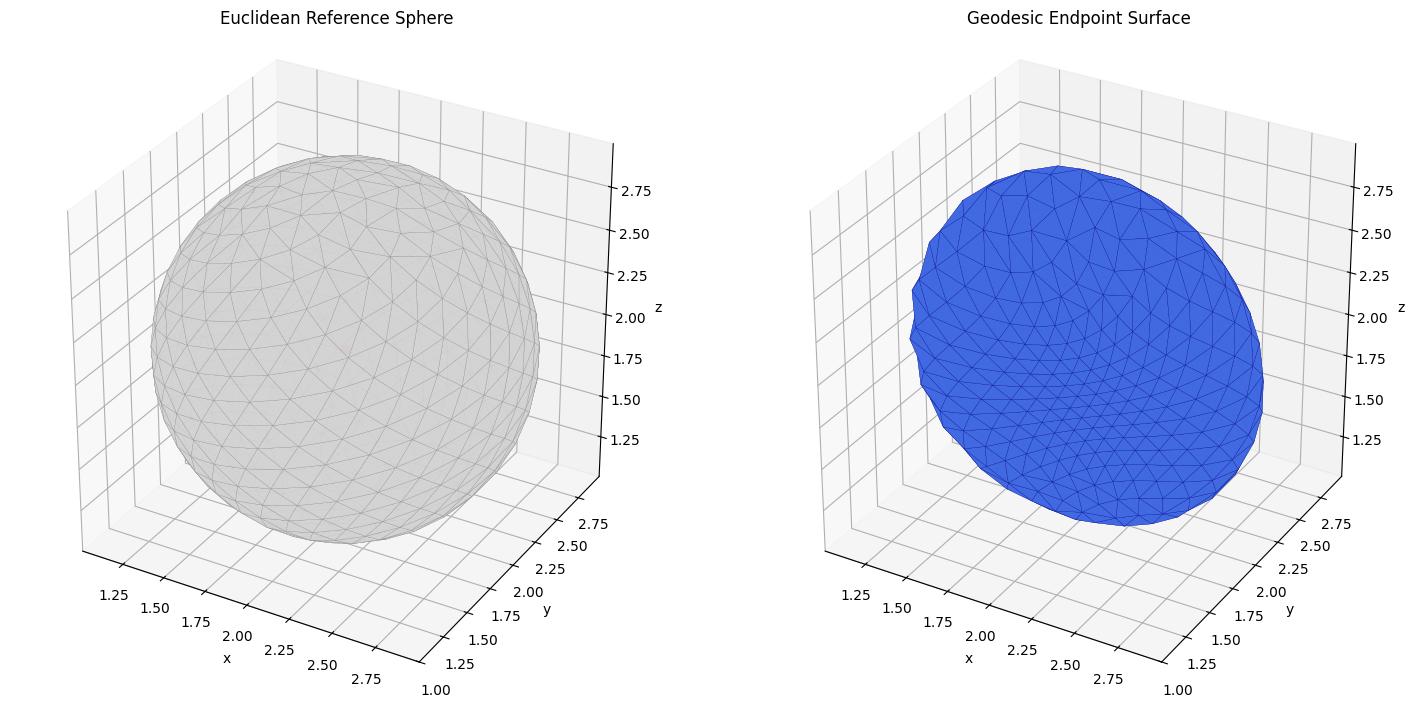

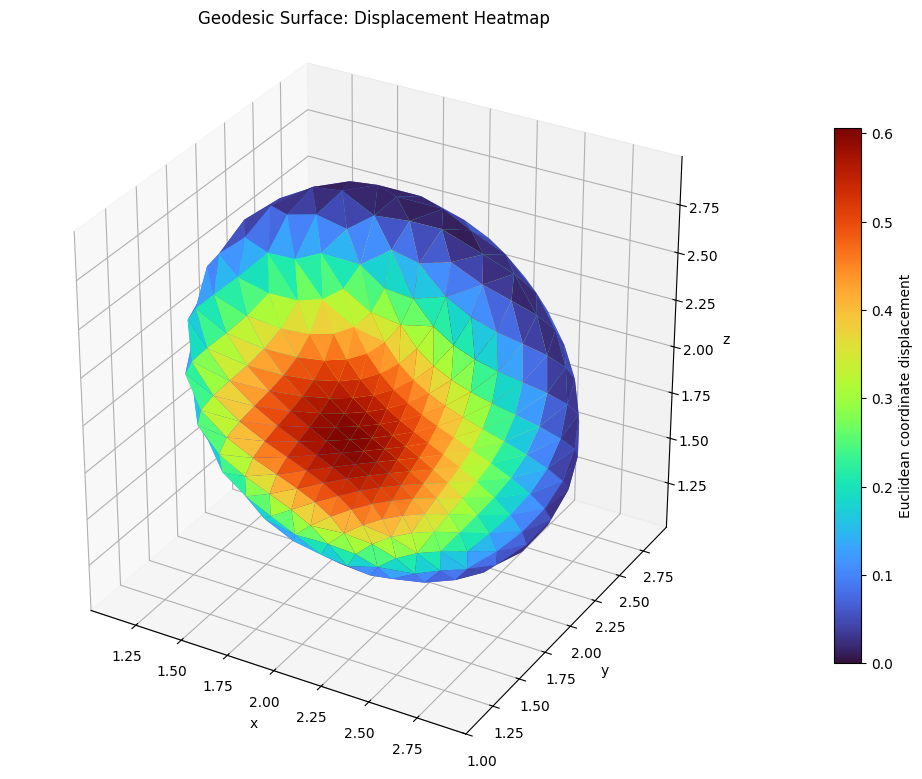

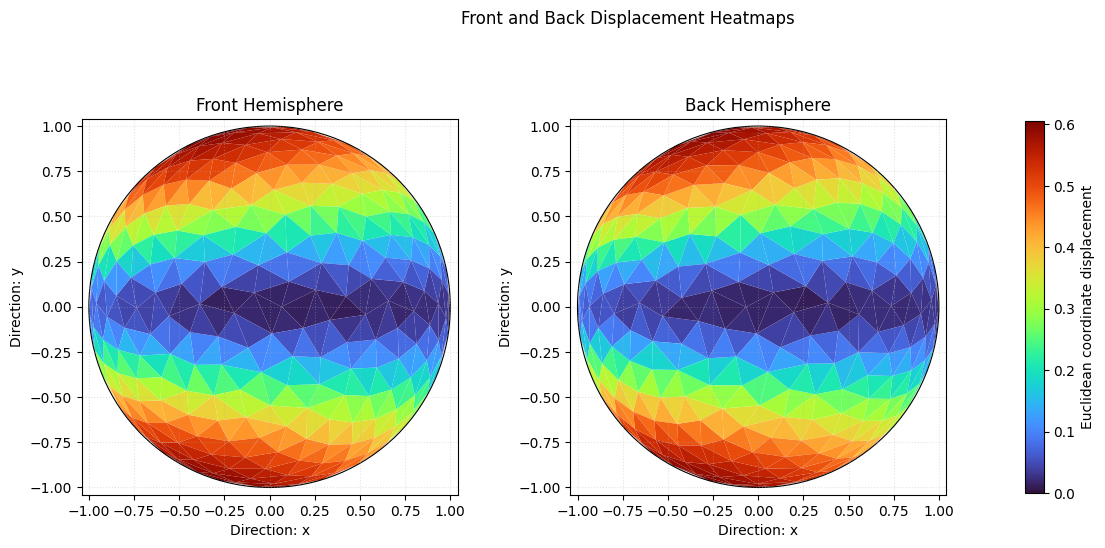


GEODESIC SURFACE COMPARISON
Center: [2. 2. 2.]
Parameter length: 1.0
Requested directions: 450
Successful geodesics: 450
Failed geodesics: 0
Triangles: 896

Coordinate displacement:
Minimum: 0.0
Maximum: 0.6062861519499363
Mean: 0.2986904711283822
RMS: 0.35298137001610946

Signed radial deviation:
Minimum: -0.49917815226550544
Maximum: 0.0
Mean: -0.23685225278349664

Note: displacement measures coordinate-space difference,
not intrinsic curvature.


In [8]:
# ============================================================
# GEODESIC SURFACE vs EUCLIDEAN SPHERE
# Four 2D heatmaps in a 2x2 layout + 3D surface comparison
#
# Requires existing variables:
#     g      : 3x3 SymPy metric matrix
#     coords : (x, y, z)
# ============================================================

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.spatial import ConvexHull
from matplotlib.tri import Triangulation
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.collections import PolyCollection
from matplotlib.patches import Circle


# ===================== SETTINGS =============================

CENTER = [2.0, 2.0, 2.0]
RADIUS = 1.0
N_DIRECTIONS = 450
N_STEPS = 100

RTOL = 1e-8
ATOL = 1e-10

SHOW_SPIKES = False
HEATMAP_CMAP = "turbo"


# ===================== VALIDATION ===========================

coords = tuple(coords)
dim = 3

if not isinstance(g, sp.MatrixBase) or g.shape != (3, 3):
    raise ValueError("g must be a 3x3 SymPy matrix.")

if len(coords) != 3:
    raise ValueError("coords must contain three coordinates.")

if RADIUS <= 0 or N_DIRECTIONS < 4:
    raise ValueError("RADIUS must be positive and N_DIRECTIONS >= 4.")

g = sp.simplify(g)
g_inv = sp.simplify(g.inv())
center = np.asarray(CENTER, dtype=float)

# ===================== CHRISTOFFEL SYMBOLS ==================

Gamma = [[[sp.S.Zero for _ in range(3)]
          for _ in range(3)] for _ in range(3)]

for i in range(3):
    for j in range(3):
        for k in range(3):
            Gamma[i][j][k] = sp.simplify(
                sp.Rational(1, 2) * sum(
                    g_inv[i, l] * (
                        sp.diff(g[l, j], coords[k])
                        + sp.diff(g[l, k], coords[j])
                        - sp.diff(g[j, k], coords[l])
                    )
                    for l in range(3)
                )
            )

Gamma_func = [
    [[sp.lambdify(coords, Gamma[i][j][k], "numpy")
      for k in range(3)] for j in range(3)]
    for i in range(3)
]

g_func = sp.lambdify(coords, g, "numpy")


def metric_at(q):
    return np.asarray(g_func(*q), dtype=float).reshape(3, 3)


def gamma_at(q):
    return np.array([
        [[float(np.asarray(Gamma_func[i][j][k](*q))
                ) for k in range(3)]
         for j in range(3)]
        for i in range(3)
    ])


g0 = metric_at(center)

if not np.all(np.isfinite(g0)):
    raise ValueError("Metric is not finite at CENTER.")

if np.min(np.linalg.eigvalsh(g0)) <= 0:
    raise ValueError("Metric must be positive-definite at CENTER.")


# ===================== UNIFORM DIRECTIONS ====================

def fibonacci_sphere(n):
    i = np.arange(n, dtype=float)
    zz = 1 - 2 * (i + 0.5) / n
    phi = np.pi * (3 - np.sqrt(5)) * i
    rr = np.sqrt(np.maximum(0, 1 - zz**2))

    return np.column_stack((
        rr * np.cos(phi),
        rr * np.sin(phi),
        zz
    ))


directions = fibonacci_sphere(N_DIRECTIONS)

# Triangulate the original direction sphere once.
direction_faces = ConvexHull(directions).simplices


# ===================== INITIAL VELOCITIES ====================

initial_velocities = []

for d in directions:
    norm2 = d @ g0 @ d
    if norm2 <= 0 or not np.isfinite(norm2):
        raise ValueError("Invalid metric norm at center.")
    initial_velocities.append(d / np.sqrt(norm2))

initial_velocities = np.asarray(initial_velocities)


# ===================== GEODESIC SYSTEM =======================

def geodesic_system(s, Y):
    q = Y[:3]
    v = Y[3:]

    if not np.all(np.isfinite(Y)):
        raise FloatingPointError("Non-finite state.")

    G = gamma_at(q)
    acceleration = -np.einsum("ijk,j,k->i", G, v, v)

    return np.concatenate((v, acceleration))


# ===================== INTEGRATE GEODESICS ===================

parameter_values = np.linspace(0, RADIUS, N_STEPS)

endpoints = np.full((N_DIRECTIONS, 3), np.nan)
paths = [None] * N_DIRECTIONS
successful = np.zeros(N_DIRECTIONS, dtype=bool)

for i, v0 in enumerate(initial_velocities):
    Y0 = np.concatenate((center, v0))

    try:
        sol = solve_ivp(
            geodesic_system,
            (0, RADIUS),
            Y0,
            t_eval=parameter_values,
            method="DOP853",
            rtol=RTOL,
            atol=ATOL
        )

        if sol.success and sol.y.shape[1] == N_STEPS:
            path = sol.y[:3].T

            if np.all(np.isfinite(path)):
                paths[i] = path
                endpoints[i] = path[-1]
                successful[i] = True

    except (ValueError, FloatingPointError, OverflowError,
            ZeroDivisionError, np.linalg.LinAlgError):
        pass


valid_indices = np.flatnonzero(successful)

if len(valid_indices) < 4:
    raise RuntimeError("Too few successful geodesics.")

geo_vertices = endpoints[valid_indices]
valid_directions = directions[valid_indices]

# Reference sphere, matched to the same initial directions.
ref_vertices = center + RADIUS * valid_directions

old_to_new = np.full(N_DIRECTIONS, -1, dtype=int)
old_to_new[valid_indices] = np.arange(len(valid_indices))

valid_faces = direction_faces[
    np.all(successful[direction_faces], axis=1)
]

faces = old_to_new[valid_faces]

if len(faces) == 0:
    raise RuntimeError("No valid triangular faces.")


# ===================== DISPLACEMENT ==========================

displacement = np.linalg.norm(
    geo_vertices - ref_vertices, axis=1
)

radial_deviation = (
    np.linalg.norm(geo_vertices - center, axis=1) - RADIUS
)

face_values = displacement[faces].mean(axis=1)

vmin = float(displacement.min())
vmax = float(displacement.max())

if np.isclose(vmin, vmax):
    vmax = vmin + 1e-12


# ===================== COMMON PLOT LIMITS ====================

all_points = np.vstack((geo_vertices, ref_vertices))
mins = all_points.min(axis=0)
maxs = all_points.max(axis=0)
mid = (mins + maxs) / 2
half = max((maxs - mins).max() / 2, 1e-8)


def set_limits(ax):
    ax.set_xlim(mid[0] - half, mid[0] + half)
    ax.set_ylim(mid[1] - half, mid[1] + half)
    ax.set_zlim(mid[2] - half, mid[2] + half)
    ax.set_box_aspect([1, 1, 1])


def add_mesh(ax, vertices, triangles, color, alpha=0.9,
             edgecolor="none"):
    mesh = Poly3DCollection(
        vertices[triangles],
        facecolors=color,
        edgecolors=edgecolor,
        linewidths=0.15,
        alpha=alpha
    )
    ax.add_collection3d(mesh)


# ===================== 3D SURFACE COMPARISON =================

fig = plt.figure(figsize=(15, 7))

ax1 = fig.add_subplot(121, projection="3d")
add_mesh(
    ax1, ref_vertices, faces,
    "lightgray", 0.85, "gray"
)
ax1.scatter(*center, color="red", s=40)
ax1.set_title("Euclidean Reference Sphere")
ax1.set_xlabel(str(coords[0]))
ax1.set_ylabel(str(coords[1]))
ax1.set_zlabel(str(coords[2]))
set_limits(ax1)

ax2 = fig.add_subplot(122, projection="3d")
add_mesh(
    ax2, geo_vertices, faces,
    "royalblue", 0.95, "navy"
)
ax2.scatter(*center, color="red", s=40)

if SHOW_SPIKES:
    for idx in valid_indices:
        p = paths[idx]
        ax2.plot(p[:, 0], p[:, 1], p[:, 2],
                 color="navy", alpha=0.3, linewidth=0.4)

ax2.set_title("Geodesic Endpoint Surface")
ax2.set_xlabel(str(coords[0]))
ax2.set_ylabel(str(coords[1]))
ax2.set_zlabel(str(coords[2]))
set_limits(ax2)

plt.tight_layout()
plt.show()


# ===================== 3D DISPLACEMENT HEATMAP ===============

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

mesh = Poly3DCollection(
    geo_vertices[faces],
    cmap=HEATMAP_CMAP,
    edgecolors="none"
)
mesh.set_array(face_values)
mesh.set_clim(vmin, vmax)

ax.add_collection3d(mesh)
ax.scatter(*center, color="black", s=25)
ax.set_title("Geodesic Surface: Displacement Heatmap")
ax.set_xlabel(str(coords[0]))
ax.set_ylabel(str(coords[1]))
ax.set_zlabel(str(coords[2]))
set_limits(ax)

fig.colorbar(
    mesh, ax=ax, shrink=0.7, pad=0.1,
    label="Euclidean coordinate displacement"
)
plt.tight_layout()
plt.show()


# ===================== TWO 2D HEATMAPS ======================

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

views = [
    (axes[0], 2, +1, "Front Hemisphere"),
    (axes[1], 2, -1, "Back Hemisphere")
]

face_centers = valid_directions[faces].mean(axis=1)
projected = valid_directions[:, [0, 1]]

last_collection = None

for ax, normal_axis, sign, title in views:

    mask = sign * face_centers[:, normal_axis] >= 0
    selected_faces = faces[mask]
    selected_values = face_values[mask]

    collection = PolyCollection(
        projected[selected_faces],
        array=selected_values,
        cmap=HEATMAP_CMAP,
        edgecolors="none"
    )
    collection.set_clim(vmin, vmax)
    ax.add_collection(collection)

    ax.add_patch(Circle(
        (0, 0), 1, fill=False,
        color="black", linewidth=0.8
    ))

    ax.set_xlim(-1.04, 1.04)
    ax.set_ylim(-1.04, 1.04)
    ax.set_aspect("equal")
    ax.set_xlabel(f"Direction: {coords[0]}")
    ax.set_ylabel(f"Direction: {coords[1]}")
    ax.set_title(title)
    ax.grid(True, linestyle=":", alpha=0.35)

    last_collection = collection

fig.subplots_adjust(
    left=0.08,
    right=0.84,
    bottom=0.12,
    top=0.85,
    wspace=0.30
)

cbar = fig.colorbar(
    last_collection,
    ax=axes.ravel().tolist(),
    location="right",
    fraction=0.045,
    pad=0.08,
    shrink=0.85
)

cbar.set_label("Euclidean coordinate displacement")

fig.suptitle("Front and Back Displacement Heatmaps")
plt.show()


# ===================== NUMERICAL REPORT ======================

print("\n" + "=" * 60)
print("GEODESIC SURFACE COMPARISON")
print("=" * 60)
print("Center:", center)
print("Parameter length:", RADIUS)
print("Requested directions:", N_DIRECTIONS)
print("Successful geodesics:", int(successful.sum()))
print("Failed geodesics:", int((~successful).sum()))
print("Triangles:", len(faces))

print("\nCoordinate displacement:")
print("Minimum:", float(displacement.min()))
print("Maximum:", float(displacement.max()))
print("Mean:", float(displacement.mean()))
print("RMS:", float(np.sqrt(np.mean(displacement**2))))

print("\nSigned radial deviation:")
print("Minimum:", float(radial_deviation.min()))
print("Maximum:", float(radial_deviation.max()))
print("Mean:", float(radial_deviation.mean()))

print("\nNote: displacement measures coordinate-space difference,")
print("not intrinsic curvature.")
print("=" * 60)

# Signed radial difference plot
This will let us know which side shrinked and which side expanded for the metric

Signed radial deviation statistics
Minimum: -0.49917815226550544
Maximum: 0.0
Mean: -0.23685225278349664


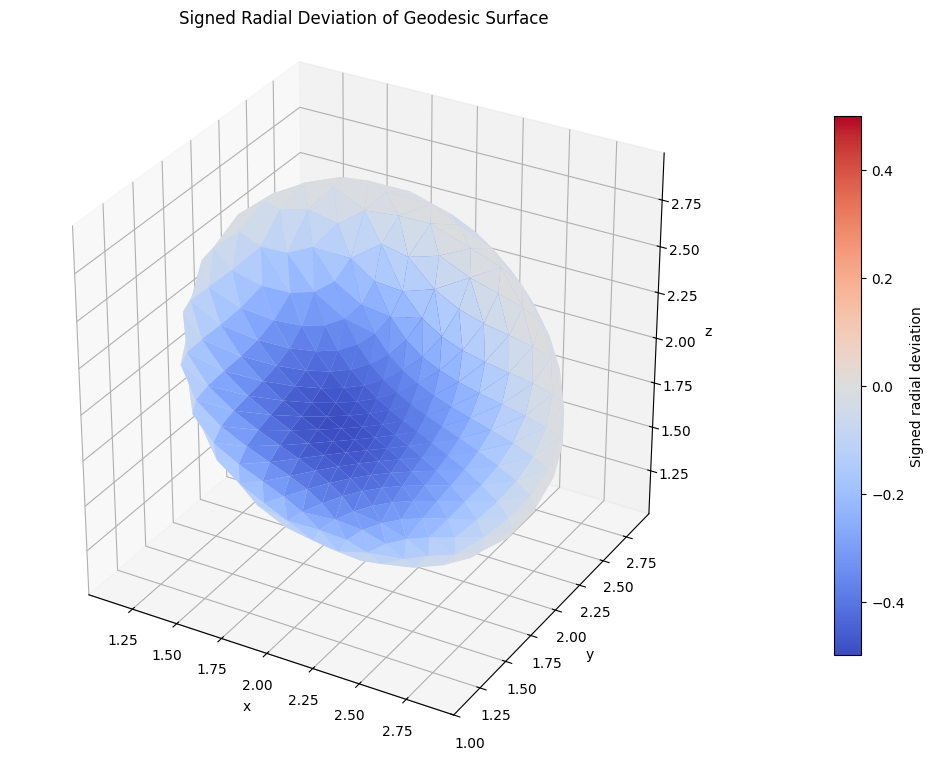

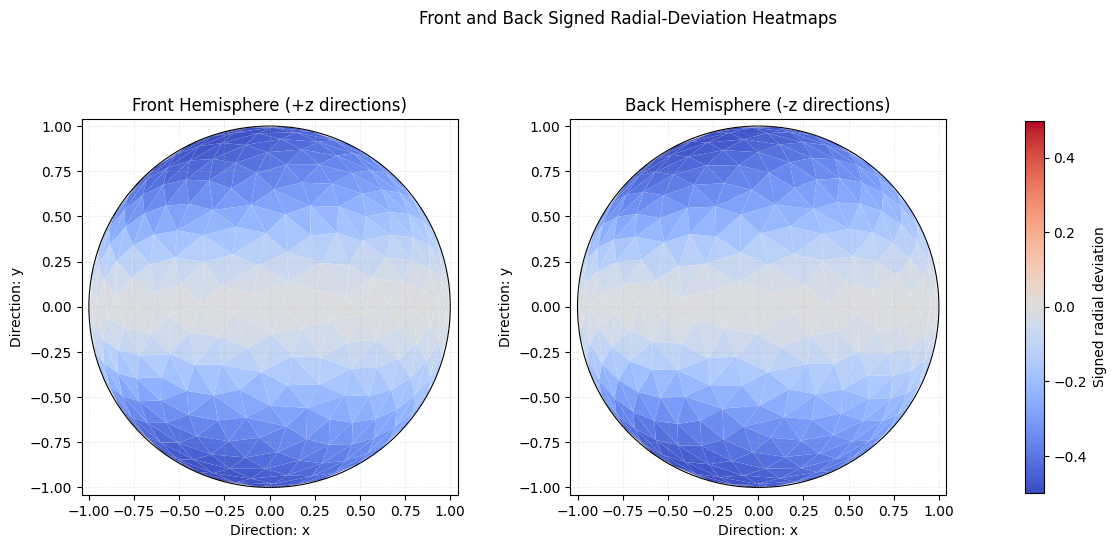

In [9]:

# ============================================================
# SIGNED RADIAL DEVIATION HEATMAPS
# Requires variables from the previous geodesic-surface code.
# ============================================================

from matplotlib.collections import PolyCollection
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import Circle
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. SIGNED RADIAL DEVIATION
# ------------------------------------------------------------

# Positive = outside reference sphere
# Negative = inside reference sphere
# Zero     = on reference sphere

radial_deviation = (
    np.linalg.norm(geo_vertices - center, axis=1) - RADIUS
)

# Mean radial deviation on each triangle
face_values = radial_deviation[faces].mean(axis=1)

# Symmetric color scale centered at zero
max_abs = max(float(np.max(np.abs(radial_deviation))), 1e-12)
vmin, vmax = -max_abs, max_abs

print("Signed radial deviation statistics")
print("Minimum:", float(radial_deviation.min()))
print("Maximum:", float(radial_deviation.max()))
print("Mean:", float(radial_deviation.mean()))

# ------------------------------------------------------------
# 2. 3D SIGNED RADIAL-DEVIATION HEATMAP
# ------------------------------------------------------------

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

mesh = Poly3DCollection(
    geo_vertices[faces],
    cmap="coolwarm",
    edgecolors="none"
)
mesh.set_array(face_values)
mesh.set_clim(vmin, vmax)

ax.add_collection3d(mesh)
ax.scatter(*center, color="black", s=25, label="Center")

# Use common spatial limits
all_points = np.vstack((geo_vertices, ref_vertices))
mins = all_points.min(axis=0)
maxs = all_points.max(axis=0)
mid = (mins + maxs) / 2
half = max((maxs - mins).max() / 2, 1e-8)

ax.set_xlim(mid[0] - half, mid[0] + half)
ax.set_ylim(mid[1] - half, mid[1] + half)
ax.set_zlim(mid[2] - half, mid[2] + half)
ax.set_box_aspect([1, 1, 1])

ax.set_xlabel(str(coords[0]))
ax.set_ylabel(str(coords[1]))
ax.set_zlabel(str(coords[2]))
ax.set_title("Signed Radial Deviation of Geodesic Surface")

fig.colorbar(
    mesh,
    ax=ax,
    shrink=0.7,
    pad=0.12,
    label="Signed radial deviation"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. TWO 2D HEATMAPS: FRONT AND BACK
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Classify triangles by their initial direction's z-component
face_centers = valid_directions[faces].mean(axis=1)

# Project initial directions onto the xy-plane
projected = valid_directions[:, [0, 1]]

views = [
    (axes[0], +1, "Front Hemisphere (+z directions)"),
    (axes[1], -1, "Back Hemisphere (-z directions)")
]

last_collection = None

for ax, sign, title in views:

    mask = sign * face_centers[:, 2] >= 0
    selected_faces = faces[mask]
    selected_values = face_values[mask]

    collection = PolyCollection(
        projected[selected_faces],
        array=selected_values,
        cmap="coolwarm",
        edgecolors="none"
    )
    collection.set_clim(vmin, vmax)
    ax.add_collection(collection)

    ax.add_patch(Circle(
        (0, 0), 1,
        fill=False,
        color="black",
        linewidth=0.8
    ))

    ax.set_xlim(-1.04, 1.04)
    ax.set_ylim(-1.04, 1.04)
    ax.set_aspect("equal")
    ax.set_xlabel(f"Direction: {coords[0]}")
    ax.set_ylabel(f"Direction: {coords[1]}")
    ax.set_title(title)
    ax.grid(True, linestyle=":", alpha=0.35)

    last_collection = collection

fig.subplots_adjust(
    left=0.08, right=0.84,
    bottom=0.12, top=0.85,
    wspace=0.30
)

fig.colorbar(
    last_collection,
    ax=axes.ravel().tolist(),
    location="right",
    fraction=0.045,
    pad=0.08,
    shrink=0.85,
    label="Signed radial deviation"
)

fig.suptitle(
    "Front and Back Signed Radial-Deviation Heatmaps"
)
plt.show()


# Volume and Surface area metrics comparison for both the spheres

Euclidean sphere with Euclidean metric and Geodesic sphere with Riemannian metric $g$

In [10]:
# ============================================================
# INTRINSIC RIEMANNIAN AREA AND VOLUME OF A GEODESIC BALL
# Revised numerical implementation
#
# Requires existing variables:
#   g       : 3x3 SymPy Riemannian metric
#   coords  : (x, y, z)
#   CENTER  : center coordinates
#   RADIUS  : geodesic radius
#
# Computes:
#   1. Intrinsic area of the geodesic sphere
#   2. Intrinsic volume of the geodesic ball
#   3. Euclidean reference area and volume
#   4. Optional grid-refinement diagnostics
#
# Validity requires the exponential map to be regular and
# injective throughout the ball (before the cut locus).
# ============================================================

import sympy as sp
import numpy as np

from scipy.integrate import solve_ivp, simpson


# ============================================================
# 1. SETTINGS
# ============================================================

N_THETA = 30
N_PHI = 60
N_RADIAL = 40

RTOL = 1e-9
ATOL = 1e-11

# Run a second calculation on a finer grid.
RUN_REFINED_CHECK = True

REFINEMENT_FACTOR = 1.5

coords = tuple(coords)
center = np.asarray(CENTER, dtype=float)

if center.shape != (3,):
    raise ValueError("CENTER must contain three coordinates.")

if not np.isfinite(RADIUS) or RADIUS <= 0:
    raise ValueError("RADIUS must be positive and finite.")

if min(N_THETA, N_PHI, N_RADIAL) < 2:
    raise ValueError("All grid interval counts must be >= 2.")


# ============================================================
# 2. VALIDATE AND LAMBDIFY THE METRIC
# ============================================================

if not isinstance(g, sp.MatrixBase) or g.shape != (3, 3):
    raise ValueError("g must be a 3x3 SymPy matrix.")

if len(coords) != 3:
    raise ValueError("coords must contain three coordinates.")

g = sp.simplify(g)

for i in range(3):
    for j in range(3):
        if sp.simplify(g[i, j] - g[j, i]) != 0:
            raise ValueError("Metric must be symmetric.")

g_inv = sp.simplify(g.inv())

g_func = sp.lambdify(coords, g, modules="numpy")


def metric_at(q):
    """Evaluate and validate the Riemannian metric at q."""

    G = np.asarray(g_func(*q), dtype=float).reshape(3, 3)

    if not np.all(np.isfinite(G)):
        raise ValueError(f"Non-finite metric at {q}.")

    # Remove insignificant floating-point asymmetry.
    G = 0.5 * (G + G.T)

    eigenvalues = np.linalg.eigvalsh(G)

    if eigenvalues[0] <= 0:
        raise ValueError(
            f"Metric is not positive-definite at {q}; "
            f"eigenvalues={eigenvalues}"
        )

    return G


G0 = metric_at(center)


# ============================================================
# 3. CHRISTOFFEL SYMBOLS
# ============================================================

Gamma = [
    [
        [
            sp.S.Zero for _ in range(3)
        ]
        for _ in range(3)
    ]
    for _ in range(3)
]

for i in range(3):
    for j in range(3):
        for k in range(3):
            Gamma[i][j][k] = sp.simplify(
                sp.Rational(1, 2) * sum(
                    g_inv[i, l] * (
                        sp.diff(g[l, j], coords[k])
                        + sp.diff(g[l, k], coords[j])
                        - sp.diff(g[j, k], coords[l])
                    )
                    for l in range(3)
                )
            )

Gamma_func = [
    [
        [
            sp.lambdify(
                coords, Gamma[i][j][k], modules="numpy"
            )
            for k in range(3)
        ]
        for j in range(3)
    ]
    for i in range(3)
]


def gamma_at(q):
    return np.array([
        [
            [
                float(np.asarray(Gamma_func[i][j][k](*q)))
                for k in range(3)
            ]
            for j in range(3)
        ]
        for i in range(3)
    ])


# ============================================================
# 4. GEODESIC EQUATION
# ============================================================

def geodesic_system(s, Y):
    q = Y[:3]
    v = Y[3:]

    Gamma_q = gamma_at(q)

    acceleration = -np.einsum(
        "ijk,j,k->i", Gamma_q, v, v
    )

    return np.concatenate((v, acceleration))


# ============================================================
# 5. METRIC-ORTHONORMAL INITIAL VELOCITIES
# ============================================================

# G0 = C @ C.T.
# Therefore v = solve(C.T, u) satisfies v.T @ G0 @ v = 1
# for every Euclidean unit vector u.

C = np.linalg.cholesky(G0)


def initial_velocity(theta, phi):
    u = np.array([
        np.cos(theta),
        np.sin(theta) * np.cos(phi),
        np.sin(theta) * np.sin(phi)
    ])

    return np.linalg.solve(C.T, u)


# ============================================================
# 6. COMPUTE AREA AND VOLUME ON ONE GRID
# ============================================================

def compute_intrinsic_quantities(
    n_theta, n_phi, n_radial
):
    theta_grid = np.linspace(
        0.0, np.pi, n_theta + 1
    )

    # Periodic grid: do not duplicate the 2*pi endpoint.
    phi_grid = (
        2.0 * np.pi
        * np.arange(n_phi) / n_phi
    )

    s_grid = np.linspace(
        0.0, RADIUS, n_radial + 1
    )

    dphi = 2.0 * np.pi / n_phi

    # Q[radial, theta, phi, coordinate]
    Q = np.empty(
        (n_radial + 1, n_theta + 1, n_phi, 3),
        dtype=float
    )

    # --------------------------------------------------------
    # Integrate radial geodesics
    # --------------------------------------------------------

    for it, theta in enumerate(theta_grid):
        for ip, phi in enumerate(phi_grid):

            v0 = initial_velocity(theta, phi)
            Y0 = np.concatenate((center, v0))

            sol = solve_ivp(
                geodesic_system,
                (0.0, RADIUS),
                Y0,
                t_eval=s_grid,
                method="DOP853",
                rtol=RTOL,
                atol=ATOL
            )

            if (
                not sol.success
                or sol.y.shape[1] != len(s_grid)
            ):
                raise RuntimeError(
                    "Geodesic integration failed at "
                    f"theta={theta}, phi={phi}: "
                    f"{sol.message}"
                )

            Q[:, it, ip, :] = sol.y[:3].T

    if not np.all(np.isfinite(Q)):
        raise ValueError(
            "Geodesic coordinates contain non-finite values."
        )

    # --------------------------------------------------------
    # Evaluate sqrt(det(g)) along the geodesic grid
    # --------------------------------------------------------

    sqrt_det_g = np.empty(
        (n_radial + 1, n_theta + 1, n_phi)
    )

    for ir in range(n_radial + 1):
        for it in range(n_theta + 1):
            for ip in range(n_phi):

                G = metric_at(Q[ir, it, ip, :])
                det_G = float(np.linalg.det(G))

                if not np.isfinite(det_G) or det_G <= 0:
                    raise ValueError(
                        "Invalid metric determinant at "
                        f"{Q[ir, it, ip, :]}"
                    )

                sqrt_det_g[ir, it, ip] = np.sqrt(det_G)

    # --------------------------------------------------------
    # Coordinate derivatives of the exponential map
    # --------------------------------------------------------

    # Radial derivative: q_s
    dq_ds = np.gradient(
        Q, s_grid, axis=0, edge_order=2
    )

    # Angular derivative: q_theta
    dq_dtheta = np.gradient(
        Q, theta_grid, axis=1, edge_order=2
    )

    # Periodic angular derivative: q_phi
    dq_dphi = (
        np.roll(Q, -1, axis=2)
        - np.roll(Q, 1, axis=2)
    ) / (2.0 * dphi)

    # --------------------------------------------------------
    # INTRINSIC SURFACE AREA
    # --------------------------------------------------------

    # Evaluate at s = RADIUS.
    qR = Q[-1]
    a = dq_dtheta[-1]
    b = dq_dphi[-1]

    area_density = np.empty(
        (n_theta + 1, n_phi)
    )

    for it in range(n_theta + 1):
        for ip in range(n_phi):

            G = metric_at(qR[it, ip])

            E = a[it, ip] @ G @ a[it, ip]
            F = a[it, ip] @ G @ b[it, ip]
            H = b[it, ip] @ G @ b[it, ip]

            det_induced = E * H - F**2

            # A negative value beyond roundoff indicates
            # a degenerate or numerically unreliable surface.
            scale = max(abs(E * H), abs(F**2), 1.0)

            if det_induced < -1e-10 * scale:
                raise ValueError(
                    "Invalid induced surface metric. "
                    "Check the geodesic map and grid resolution."
                )

            area_density[it, ip] = np.sqrt(
                max(det_induced, 0.0)
            )

    # The density already includes the angular coordinate
    # Jacobian through q_theta and q_phi.
    # Do NOT multiply by sin(theta) again.
    area_theta = simpson(
        area_density, x=theta_grid, axis=0
    )

    intrinsic_area = float(
        np.sum(area_theta) * dphi
    )

    # --------------------------------------------------------
    # INTRINSIC VOLUME
    # --------------------------------------------------------

    # J has columns q_s, q_theta, q_phi.
    # Its determinant is the coordinate Jacobian.
    J = np.stack(
        [dq_ds, dq_dtheta, dq_dphi],
        axis=-1
    )

    coordinate_jacobian = np.abs(
        np.linalg.det(J)
    )

    volume_density = (
        sqrt_det_g * coordinate_jacobian
    )

    # Periodic phi integration using the periodic trapezoidal
    # rule: sum over all samples, multiply by the grid spacing.
    volume_theta = (
        np.sum(volume_density, axis=2) * dphi
    )

    # Integrate over theta, then radial distance.
    volume_radial = simpson(
        volume_theta, x=theta_grid, axis=1
    )

    intrinsic_volume = float(
        simpson(volume_radial, x=s_grid)
    )

    return {
        "area": intrinsic_area,
        "volume": intrinsic_volume,
        "n_theta": n_theta,
        "n_phi": n_phi,
        "n_radial": n_radial
    }


# ============================================================
# 7. BASE CALCULATION
# ============================================================

base = compute_intrinsic_quantities(
    N_THETA, N_PHI, N_RADIAL
)

intrinsic_area = base["area"]
intrinsic_volume = base["volume"]


# ============================================================
# 8. EUCLIDEAN REFERENCE VALUES
# ============================================================

euclidean_area = 4.0 * np.pi * RADIUS**2

euclidean_volume = (
    4.0 / 3.0
) * np.pi * RADIUS**3

area_difference = intrinsic_area - euclidean_area
volume_difference = intrinsic_volume - euclidean_volume

area_percent = (
    100.0 * area_difference / euclidean_area
)

volume_percent = (
    100.0 * volume_difference / euclidean_volume
)


# ============================================================
# 9. OPTIONAL GRID-REFINEMENT CHECK
# ============================================================

refined = None

if RUN_REFINED_CHECK:

    nt2 = int(round(N_THETA * REFINEMENT_FACTOR))
    np2 = int(round(N_PHI * REFINEMENT_FACTOR))
    nr2 = int(round(N_RADIAL * REFINEMENT_FACTOR))

    # Ensure valid minimum grid sizes.
    nt2 = max(nt2, N_THETA + 1)
    np2 = max(np2, N_PHI + 1)
    nr2 = max(nr2, N_RADIAL + 1)

    refined = compute_intrinsic_quantities(
        nt2, np2, nr2
    )

    area_convergence = (
        100.0 * (refined["area"] - intrinsic_area)
        / max(abs(refined["area"]), 1e-15)
    )

    volume_convergence = (
        100.0 * (refined["volume"] - intrinsic_volume)
        / max(abs(refined["volume"]), 1e-15)
    )


# ============================================================
# 10. REPORT
# ============================================================

print("\n" + "=" * 72)
print("INTRINSIC RIEMANNIAN GEODESIC BALL COMPARISON")
print("=" * 72)

print("Center:", center)
print("Geodesic radius:", RADIUS)

print("\nBASE GRID")
print("-" * 72)
print("Theta intervals:", N_THETA)
print("Phi intervals:", N_PHI)
print("Radial intervals:", N_RADIAL)

print("\nSURFACE AREA")
print("-" * 72)
print(f"Euclidean reference area : {euclidean_area:.10f}")
print(f"Riemannian sphere area   : {intrinsic_area:.10f}")
print(f"Difference               : {area_difference:+.10f}")
print(f"Percentage difference    : {area_percent:+.6f}%")

print("\nVOLUME")
print("-" * 72)
print(f"Euclidean reference volume: {euclidean_volume:.10f}")
print(f"Riemannian ball volume   : {intrinsic_volume:.10f}")
print(f"Difference               : {volume_difference:+.10f}")
print(f"Percentage difference    : {volume_percent:+.6f}%")

if refined is not None:

    print("\nGRID-REFINEMENT DIAGNOSTICS")
    print("-" * 72)
    print(
        "Refined grid:",
        refined["n_theta"], "x",
        refined["n_phi"], "x",
        refined["n_radial"]
    )

    print(
        f"Refined sphere area : {refined['area']:.10f}"
    )
    print(
        f"Refined ball volume : {refined['volume']:.10f}"
    )

    print(
        f"Area change vs base : {area_convergence:+.6f}%"
    )
    print(
        f"Volume change vs base: {volume_convergence:+.6f}%"
    )

    print(
        "\nSmall changes suggest numerical stability; "
        "they do not by themselves prove convergence."
    )

print("\nMATHEMATICAL CONDITIONS")
print("-" * 72)
print("The metric must remain smooth and positive-definite.")
print("The exponential map must be injective over the ball.")
print("The numerical Jacobian is estimated using finite differences.")
print("Results should be checked at successively finer resolutions.")
print("=" * 72)


INTRINSIC RIEMANNIAN GEODESIC BALL COMPARISON
Center: [2. 2. 2.]
Geodesic radius: 1.0

BASE GRID
------------------------------------------------------------------------
Theta intervals: 30
Phi intervals: 60
Radial intervals: 40

SURFACE AREA
------------------------------------------------------------------------
Euclidean reference area : 12.5663706144
Riemannian sphere area   : 12.5208785515
Difference               : -0.0454920628
Percentage difference    : -0.362014%

VOLUME
------------------------------------------------------------------------
Euclidean reference volume: 4.1887902048
Riemannian ball volume   : 4.1735465537
Difference               : -0.0152436511
Percentage difference    : -0.363915%

GRID-REFINEMENT DIAGNOSTICS
------------------------------------------------------------------------
Refined grid: 45 x 90 x 60
Refined sphere area : 12.5461407142
Refined ball volume : 4.1820115974
Area change vs base : +0.201354%
Volume change vs base: +0.202416%

Small changes